# Breast cancer prediction with a small quantum kernel SVM

This notebook compares a simulated quantum support vector machine (QSVM) with classical models on the Wisconsin Diagnostic Breast Cancer (WDBC) data. The patient label is `1` for malignant and `0` for benign. A quantum feature map turns a short list of patient measurements into a quantum state; the kernel records how similar two such states are.

The reference paper by Islam et al. studies classical models and SHAP on a separate 500-patient Bangladeshi dataset. It does not study quantum computing. This project follows its classical comparison and explainability ideas on WDBC, then adds simulated QSVM experiments.

## Setup

This step imports the libraries, sets the random seed, and creates the folder for tables and figures. The installed package versions are printed so the run can be repeated and checked.

In [1]:
# Import the libraries used in the notebook.
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Import the project helpers for metrics and saved figures.
from helpers import classification_metrics, save_figure

# Use one seed for the main split, cross-validation, and model randomness.
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Create the results folders if they do not already exist.
PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
KERNEL_DIR = RESULTS_DIR / "kernels"
KERNEL_CACHE_VERSION = "fidelity-no-psd-v1"
RESULTS_DIR.mkdir(exist_ok=True)
KERNEL_DIR.mkdir(exist_ok=True)

# Print the package versions used for this run.
print("Python packages:")
print("  scikit-learn:", sklearn.__version__)
print("  numpy:", np.__version__)
print("  pandas:", pd.__version__)
print("  xgboost:", xgboost.__version__)
print("  shap:", shap.__version__)

# Set simple plot defaults for consistent saved figures.
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

Python packages:
  scikit-learn: 1.8.0
  numpy: 2.3.3
  pandas: 2.3.3
  xgboost: 3.2.0
  shap: 0.51.0


## Step 1: Load and inspect the data

We first try the UCI repository. If it cannot be reached, we use scikit-learn's bundled copy of the same WDBC dataset. We remove an ID column if present and make malignant the positive class (`1`).

In [2]:
# Try the UCI download first, then use scikit-learn's bundled copy if offline.
try:
    from ucimlrepo import fetch_ucirepo

    wdbc_data = fetch_ucirepo(id=17)
    X = wdbc_data.data.features.copy()
    target_values = wdbc_data.data.targets.iloc[:, 0].astype(str).str.strip().str.upper()

    # Drop identifier columns because they do not describe a tumor.
    identifier_columns = [name for name in X.columns if str(name).strip().lower() in {"id", "sample code"}]
    X = X.drop(columns=identifier_columns)

    # Convert the UCI labels so malignant is 1 and benign is 0.
    y = target_values.map({"M": 1, "B": 0})
    if y.isna().any():
        raise ValueError("The UCI diagnosis labels were not M or B.")
    DATA_SOURCE = "UCI Machine Learning Repository, dataset 17"
except Exception as download_error:
    from sklearn.datasets import load_breast_cancer

    # Load the identical 569-patient WDBC copy included with scikit-learn.
    breast_cancer = load_breast_cancer()
    X = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)

    # scikit-learn labels malignant as 0, so flip it to make malignant positive.
    y = pd.Series((breast_cancer.target == 0).astype(int), name="malignant")
    DATA_SOURCE = "scikit-learn bundled copy of WDBC (UCI fetch unavailable)"
    print("UCI download unavailable:", type(download_error).__name__)

# Use scikit-learn's familiar WDBC feature names for UCI's numbered names.
from sklearn.datasets import load_breast_cancer
if X.shape[1] == len(load_breast_cancer().feature_names):
    X.columns = load_breast_cancer().feature_names

# Keep the feature table numeric and reset row indexes for clear patient references.
X = X.apply(pd.to_numeric).reset_index(drop=True)
y = pd.Series(np.asarray(y, dtype=int), name="malignant")

# Print the data source, dimensions, missing values, and class counts.
print("Data source:", DATA_SOURCE)
print("Feature table shape:", X.shape)
print("Missing feature values:", int(X.isna().sum().sum()))
print("Class counts (0 = benign, 1 = malignant):")
print(y.value_counts().sort_index().rename(index={0: "Benign", 1: "Malignant"}))

# Save a small text record of which dataset source was used.
(RESULTS_DIR / "data_source.txt").write_text(DATA_SOURCE, encoding="utf-8")

UCI download unavailable: DatasetNotFoundError
Data source: scikit-learn bundled copy of WDBC (UCI fetch unavailable)
Feature table shape: (569, 30)
Missing feature values: 0
Class counts (0 = benign, 1 = malignant):
malignant
Benign       357
Malignant    212
Name: count, dtype: int64


57

WDBC has many highly correlated measurements, so PCA can compress them into a few components for the simulator.

These three plots show the class balance, relationships between features, and four example measurements by diagnosis.

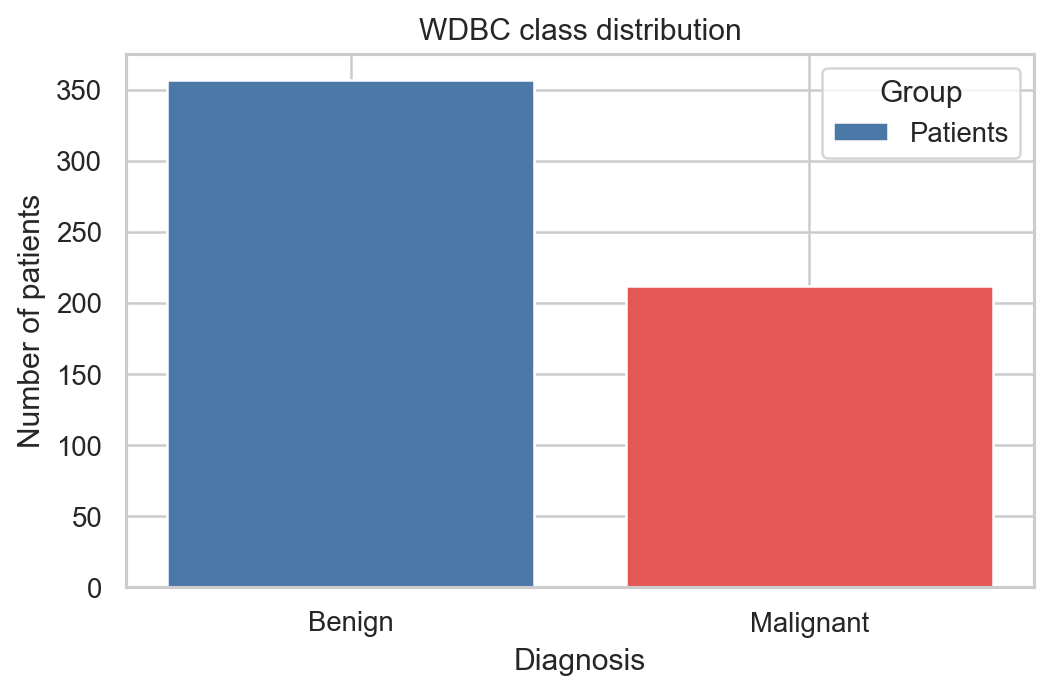

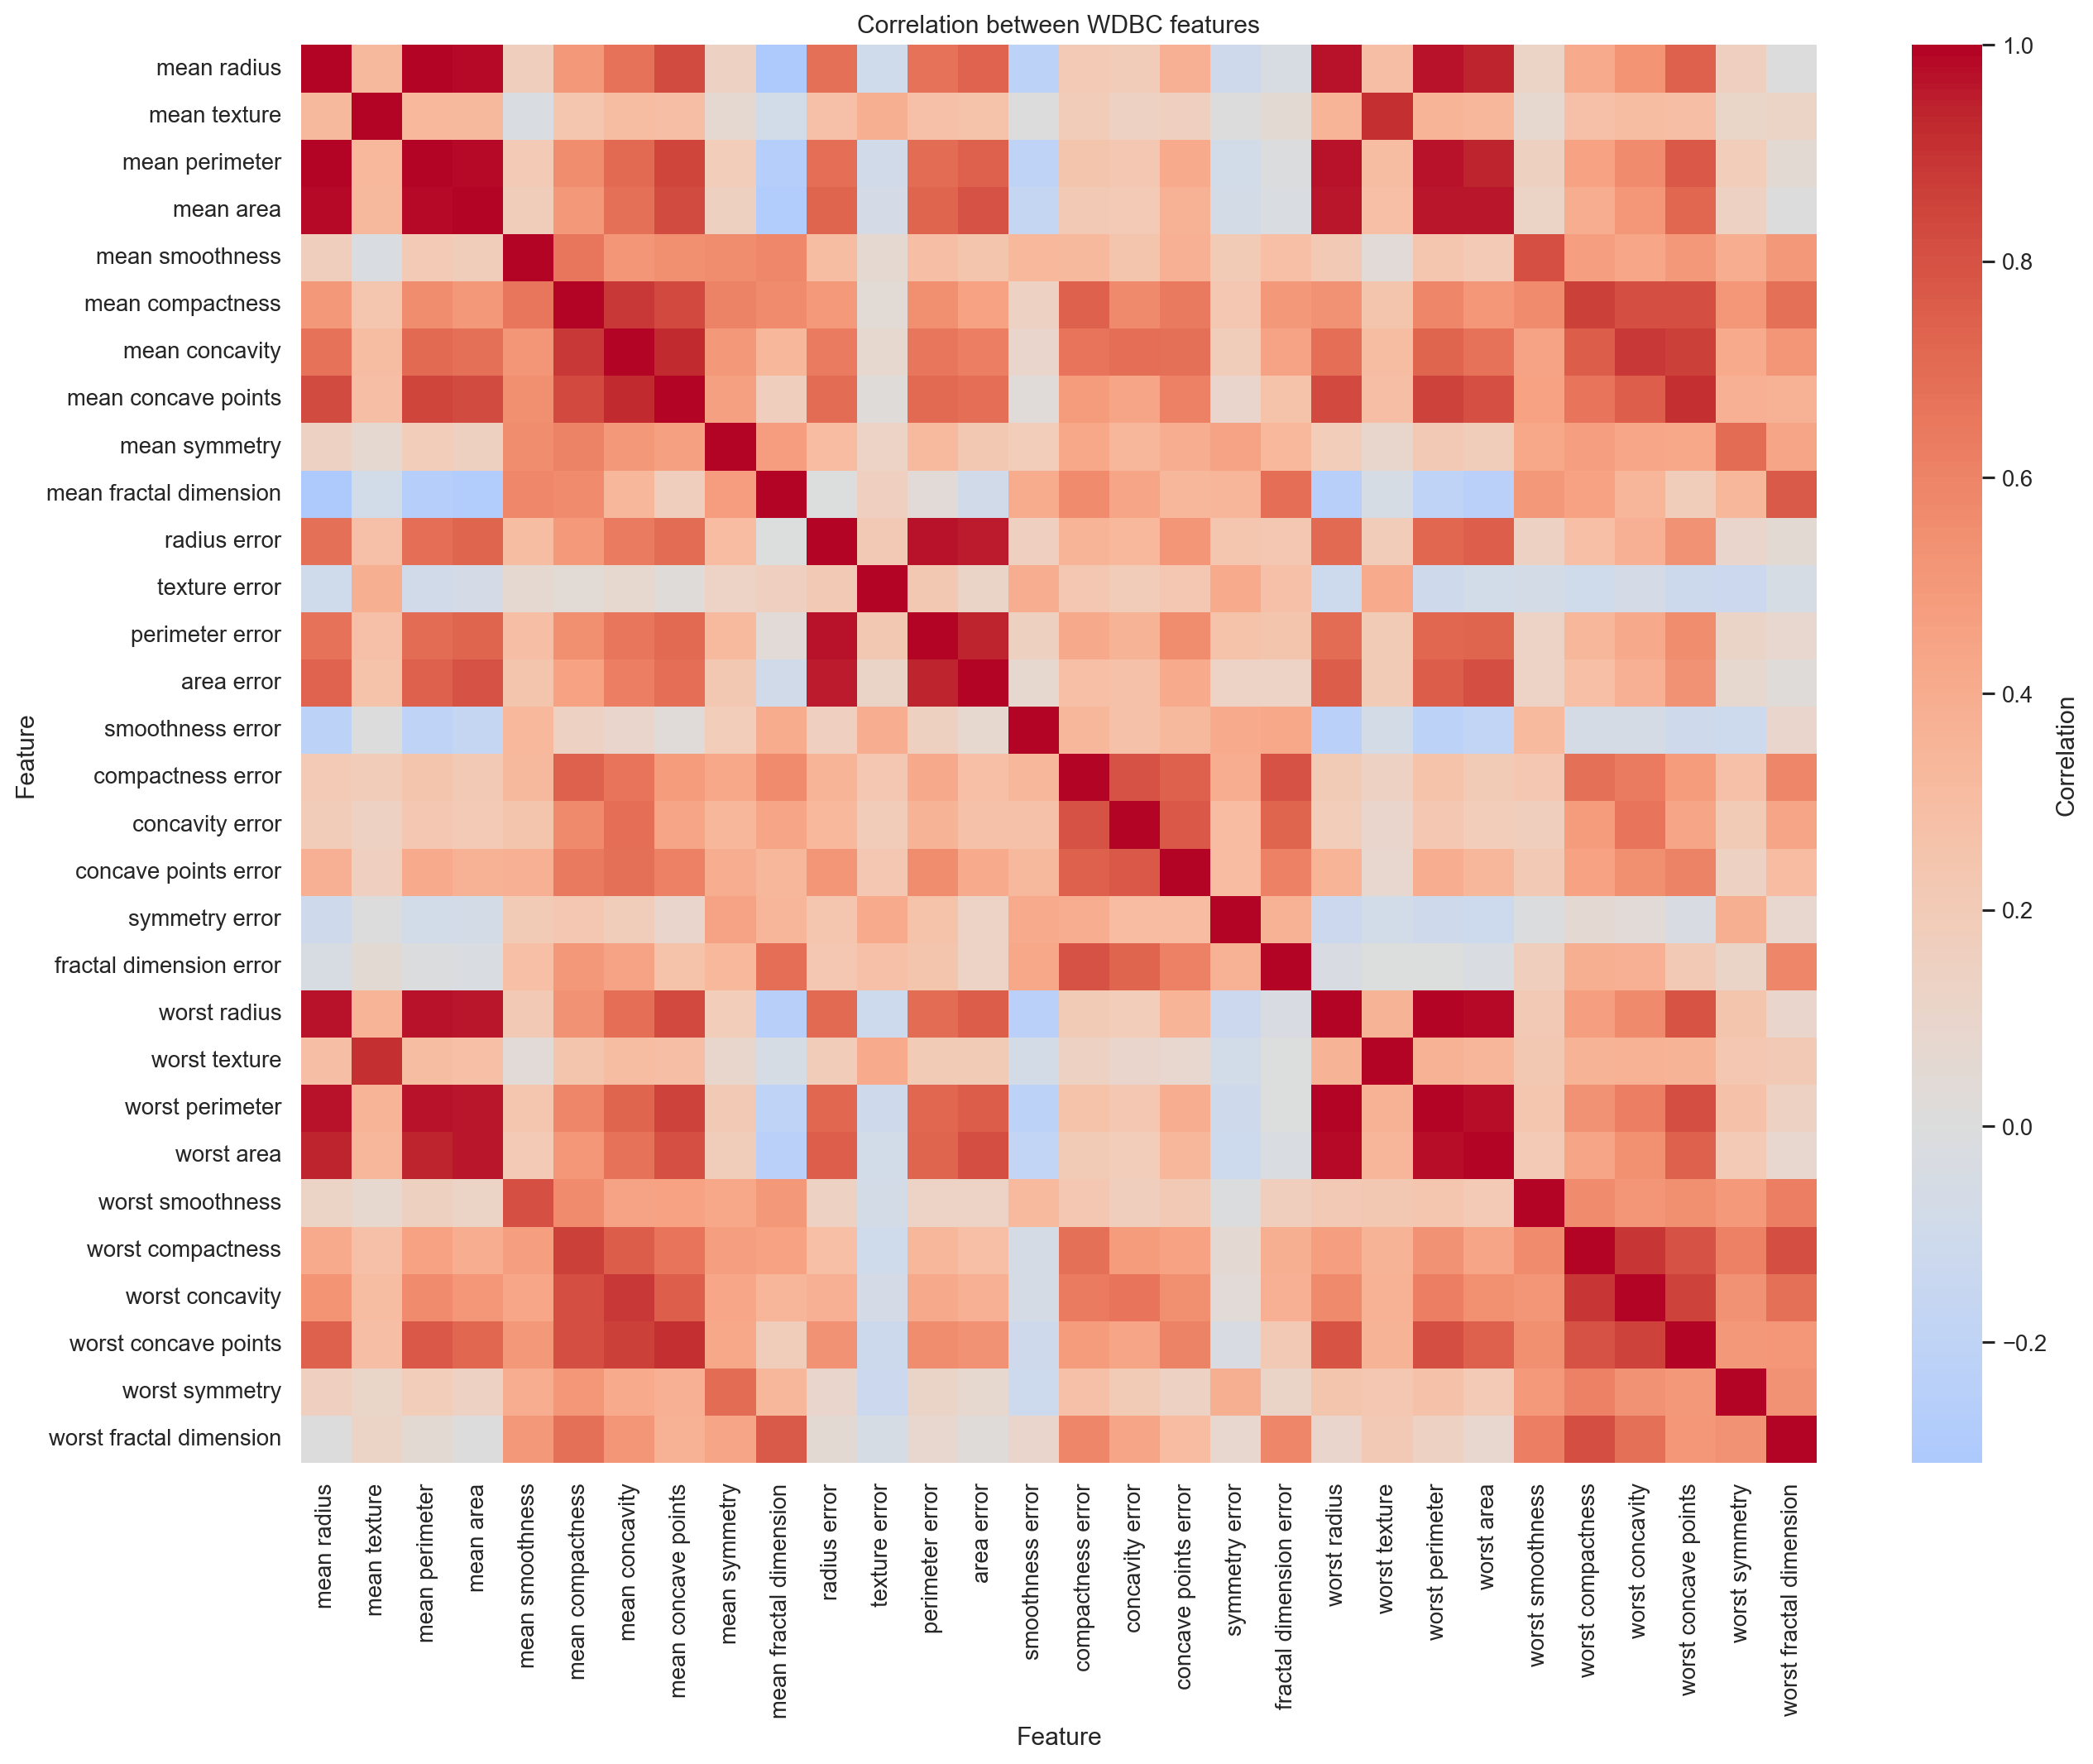

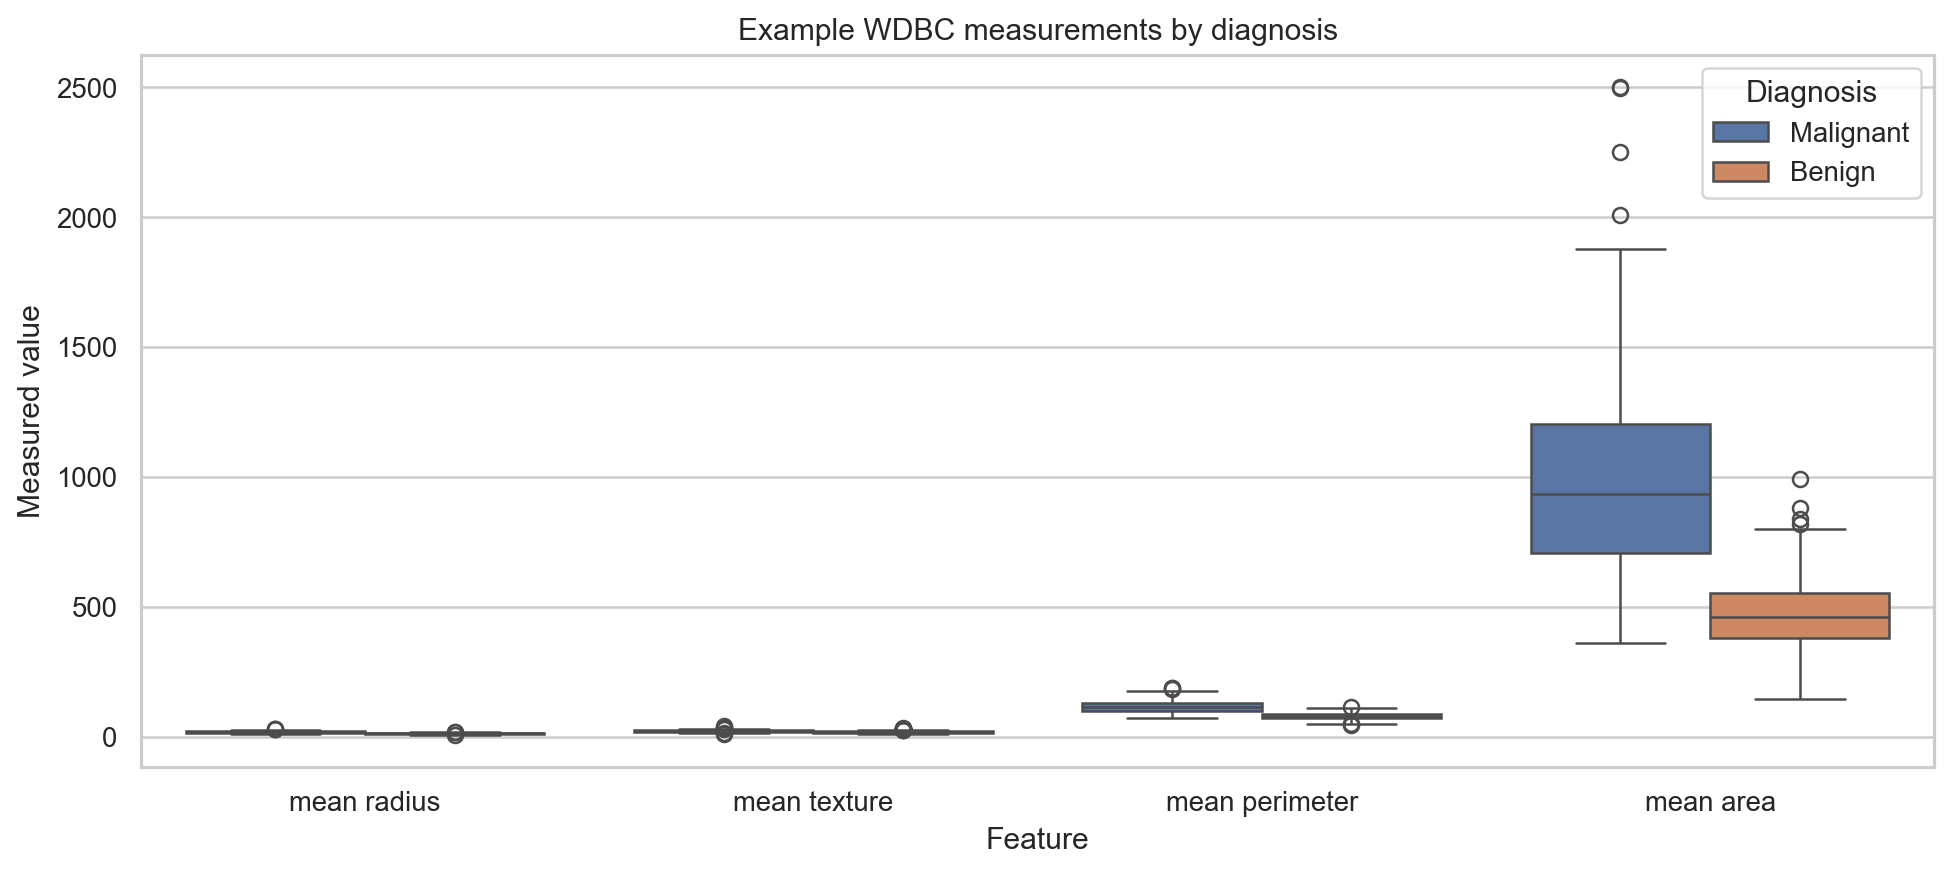

Saved the three Step 1 figures in results/.


In [3]:
# Give each target value a readable name for the plots.
diagnosis = y.map({0: "Benign", 1: "Malignant"})

# Plot how many benign and malignant cases are present.
fig, ax = plt.subplots(figsize=(6, 4))
class_counts = diagnosis.value_counts().reindex(["Benign", "Malignant"])
bars = ax.bar(class_counts.index, class_counts.values, color=["#4C78A8", "#E45756"], label="Patients")
ax.set_title("WDBC class distribution")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of patients")
ax.legend(title="Group")
save_figure(fig, RESULTS_DIR / "01_class_distribution.png")

# Plot correlations among all original measurements.
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "Correlation"})
ax.set_title("Correlation between WDBC features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
save_figure(fig, RESULTS_DIR / "02_correlation_heatmap.png")

# Plot four familiar measurements, grouped by diagnosis.
box_features = ["mean radius", "mean texture", "mean perimeter", "mean area"]
box_data = X[box_features].copy()
box_data["Diagnosis"] = diagnosis
box_long = box_data.melt(id_vars="Diagnosis", var_name="Feature", value_name="Value")
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=box_long, x="Feature", y="Value", hue="Diagnosis", ax=ax)
ax.set_title("Example WDBC measurements by diagnosis")
ax.set_xlabel("Feature")
ax.set_ylabel("Measured value")
ax.legend(title="Diagnosis")
save_figure(fig, RESULTS_DIR / "03_feature_boxplots.png")

print("Saved the three Step 1 figures in results/.")

## Step 2: Split and scale without leakage

We make a stratified 80/20 split so both sets keep a similar malignant/benign balance. Scalers are fit only on the training set. The model pipelines later repeat scaling inside each cross-validation fold, so validation rows do not affect the fitted scaler.

In [4]:
# Split row numbers so the original patient indexes can be saved and inspected.
all_row_numbers = np.arange(len(y))
train_indices, test_indices = train_test_split(
    all_row_numbers,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)

# Select the train and test rows from the original table.
X_train = X.iloc[train_indices].reset_index(drop=True)
X_test = X.iloc[test_indices].reset_index(drop=True)
y_train = y.iloc[train_indices].reset_index(drop=True)
y_test = y.iloc[test_indices].reset_index(drop=True)

# Fit a standard scaler using training data only for PCA preparation.
pca_input_scaler = StandardScaler()
X_train_scaled = pca_input_scaler.fit_transform(X_train)
X_test_scaled = pca_input_scaler.transform(X_test)

# Print the split sizes and malignant counts.
print("Training rows:", len(y_train), " Test rows:", len(y_test))
print("Training malignant cases:", int(y_train.sum()))
print("Test malignant cases:", int(y_test.sum()))

Training rows: 455  Test rows: 114
Training malignant cases: 170
Test malignant cases: 42


## Step 3: Reduce features for the simulator

The original data has 30 features. We use PCA fit on the training set and keep 4 components for the main quantum comparison; we also prepare 6 and 8 components for small follow-up runs. Each component becomes one qubit. A MinMaxScaler fitted on training components maps the quantum inputs to rotation angles from 0 to π.

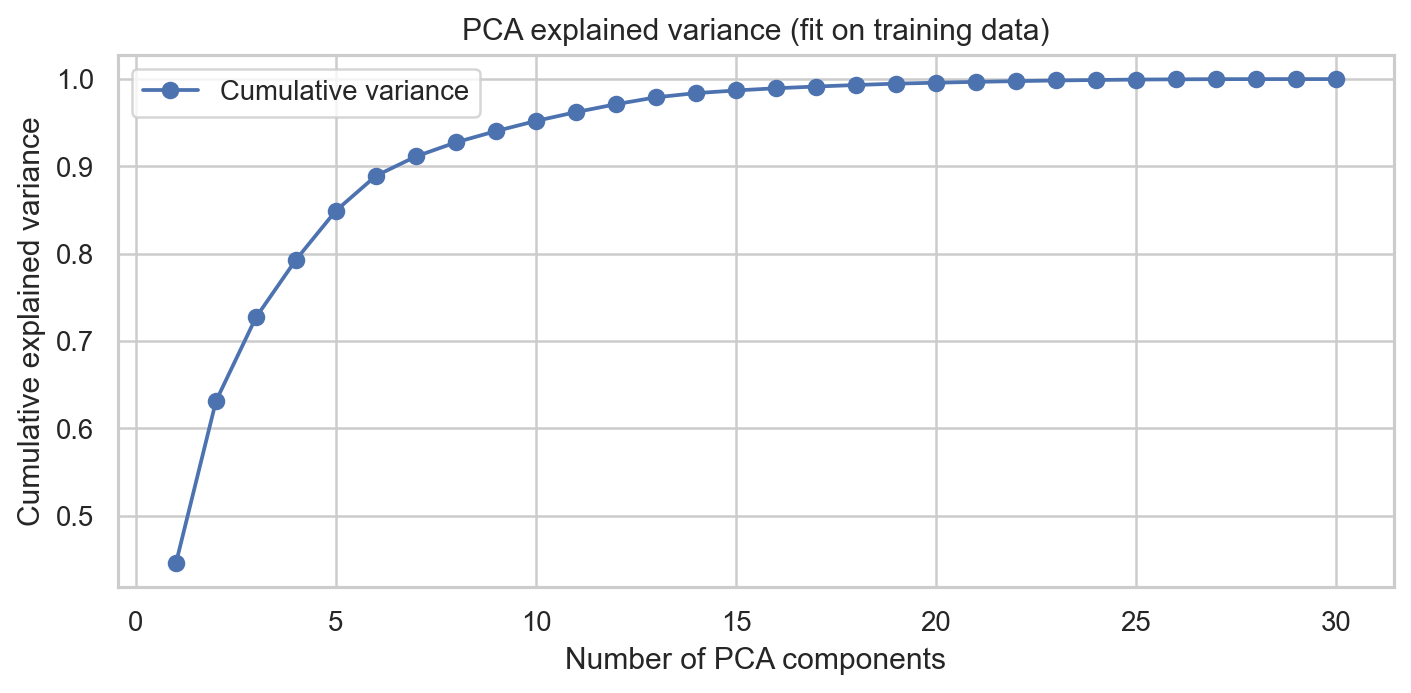

,component,rank_by_absolute_loading,original_feature,loading
0,1,1,mean concave points,0.260383
1,1,2,mean concavity,0.257761
2,1,3,worst concave points,0.249367
3,1,4,mean compactness,0.241928
4,1,5,worst perimeter,0.235494
5,2,1,mean fractal dimension,0.366648
6,2,2,worst fractal dimension,0.277471
7,2,3,fractal dimension error,0.276203
8,2,4,mean radius,-0.239776
9,2,5,mean area,-0.236925


4 qubits: 4 features; training angle range: 0.0 to 3.142
6 qubits: 6 features; training angle range: 0.0 to 3.142
8 qubits: 8 features; training angle range: 0.0 to 3.142


In [5]:
# Fit PCA using only the standardized training patients.
pca_all = PCA(n_components=X_train.shape[1], random_state=RANDOM_SEED)
X_train_pca_all = pca_all.fit_transform(X_train_scaled)
X_test_pca_all = pca_all.transform(X_test_scaled)

# Plot how much of the training-set variation the PCA components explain.
fig, ax = plt.subplots(figsize=(8, 4))
component_numbers = np.arange(1, len(pca_all.explained_variance_ratio_) + 1)
ax.plot(component_numbers, np.cumsum(pca_all.explained_variance_ratio_), marker="o", label="Cumulative variance")
ax.set_title("PCA explained variance (fit on training data)")
ax.set_xlabel("Number of PCA components")
ax.set_ylabel("Cumulative explained variance")
ax.legend()
save_figure(fig, RESULTS_DIR / "04_pca_explained_variance.png")

# Record the original features with the largest absolute loading in each of four components.
loading_rows = []
for component_number in range(4):
    component_loadings = pca_all.components_[component_number]
    largest_features = np.argsort(np.abs(component_loadings))[::-1][:5]
    for rank, feature_index in enumerate(largest_features, start=1):
        loading_rows.append({
            "component": component_number + 1,
            "rank_by_absolute_loading": rank,
            "original_feature": X.columns[feature_index],
            "loading": component_loadings[feature_index],
        })
pca_loading_table = pd.DataFrame(loading_rows)
pca_loading_table.to_csv(RESULTS_DIR / "pca_loadings_top_features.csv", index=False)
display(pca_loading_table)

# Scale the first 4, 6, and 8 PCA components to the quantum angle range.
quantum_features = {}
for qubit_count in [4, 6, 8]:
    angle_scaler = MinMaxScaler(feature_range=(0, np.pi))
    X_train_angles = angle_scaler.fit_transform(X_train_pca_all[:, :qubit_count])
    X_test_angles = angle_scaler.transform(X_test_pca_all[:, :qubit_count])
    quantum_features[qubit_count] = {
        "X_train": X_train_angles,
        "X_test": X_test_angles,
        "angle_scaler": angle_scaler,
    }

# Print the feature widths and confirm the training angles use the requested range.
for qubit_count, data in quantum_features.items():
    print(
        qubit_count,
        "qubits:",
        data["X_train"].shape[1],
        "features; training angle range:",
        round(float(data["X_train"].min()), 3),
        "to",
        round(float(data["X_train"].max()), 3),
    )

## Step 4: Classical baselines

We tune seven classical models with stratified 5-fold cross-validation. Each model is evaluated on all 30 features and on 4 PCA components. Scaling and PCA are inside each pipeline, so each cross-validation fold learns preprocessing from its own training rows only. F1 is used for tuning because malignant recall is especially important.

In [6]:
# Create the seven requested models and short parameter grids for one random seed.
def get_model_specs(seed):
    return {
        "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=seed), {"model__C": [0.1, 1, 10]}),
        "Decision Tree": (DecisionTreeClassifier(random_state=seed), {"model__max_depth": [None, 3, 6]}),
        "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1), {"model__max_depth": [None, 8]}),
        "Naive Bayes": (GaussianNB(), {"model__var_smoothing": [1e-9, 1e-8, 1e-7]}),
        "XGBoost": (XGBClassifier(n_estimators=80, eval_metric="logloss", random_state=seed, n_jobs=1, verbosity=0), {"model__max_depth": [2, 3], "model__learning_rate": [0.05, 0.1]}),
        "SVM (RBF)": (SVC(kernel="rbf"), {"model__C": [0.1, 1, 10]}),
        "SVM (linear)": (SVC(kernel="linear"), {"model__C": [0.1, 1, 10]}),
    }

# Build a pipeline that scales and optionally reduces features inside each CV fold.
def make_classical_pipeline(estimator, use_pca):
    steps = [("scale", StandardScaler())]
    if use_pca:
        steps.append(("pca", PCA(n_components=4, random_state=RANDOM_SEED)))
    steps.append(("model", estimator))
    return Pipeline(steps)

# Set up one stratified 5-fold split for the main model search.
main_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
model_specs = get_model_specs(RANDOM_SEED)
classical_rows = []
classical_searches = {}
classical_predictions = {}

# Tune and score every model on all features and on the 4-component PCA pipeline.
for feature_set, use_pca in [("All 30 features", False), ("PCA 4 components", True)]:
    for model_name, (estimator, parameter_grid) in model_specs.items():
        pipeline = make_classical_pipeline(clone(estimator), use_pca)
        search = GridSearchCV(
            pipeline,
            parameter_grid,
            scoring="f1",
            cv=main_cv,
            n_jobs=1,
            refit=True,
        )
        start_time = time.time()
        search.fit(X_train, y_train)
        training_seconds = time.time() - start_time

        # Predict malignant labels and decision scores on the untouched test set.
        y_prediction = search.predict(X_test)
        if hasattr(search.best_estimator_, "decision_function"):
            y_score = search.decision_function(X_test)
        else:
            y_score = search.predict_proba(X_test)[:, 1]
        scores = classification_metrics(y_test, y_prediction, y_score)

        # Save the fitted search, predictions, and real test metrics.
        key = (model_name, feature_set)
        classical_searches[key] = search
        classical_predictions[key] = {"y_pred": y_prediction, "y_score": y_score}
        classical_rows.append({
            "model": model_name,
            "features_used": feature_set,
            **scores,
            "training_time_s": training_seconds,
            "best_parameters": str(search.best_params_),
            "cv_f1": search.best_score_,
        })
        print(feature_set, "|", model_name, "| test F1:", round(scores["f1"], 3), "| time:", round(training_seconds, 2), "s")

# Display and save the classical model comparison.
classical_results = pd.DataFrame(classical_rows).sort_values(["features_used", "f1"], ascending=[True, False])
classical_results.to_csv(RESULTS_DIR / "classical_results.csv", index=False)
display(classical_results)

All 30 features | Logistic Regression | test F1: 0.951 | time: 0.19 s
All 30 features | Decision Tree | test F1: 0.905 | time: 0.19 s


All 30 features | Random Forest | test F1: 0.963 | time: 1.84 s
All 30 features | Naive Bayes | test F1: 0.889 | time: 0.1 s


All 30 features | XGBoost | test F1: 0.95 | time: 1.19 s
All 30 features | SVM (RBF) | test F1: 0.963 | time: 0.14 s


All 30 features | SVM (linear) | test F1: 0.976 | time: 0.15 s
PCA 4 components | Logistic Regression | test F1: 0.963 | time: 0.17 s


PCA 4 components | Decision Tree | test F1: 0.914 | time: 0.15 s


PCA 4 components | Random Forest | test F1: 0.938 | time: 1.55 s
PCA 4 components | Naive Bayes | test F1: 0.861 | time: 0.14 s


PCA 4 components | XGBoost | test F1: 0.911 | time: 0.51 s
PCA 4 components | SVM (RBF) | test F1: 0.925 | time: 0.16 s


PCA 4 components | SVM (linear) | test F1: 0.963 | time: 0.12 s


,model,features_used,accuracy,precision,recall,f1,roc_auc,training_time_s,best_parameters,cv_f1
6,SVM (linear),All 30 features,0.982456,1.000000,0.952381,0.975610,0.996362,0.146050,{'model__C': 0.1},0.954817
2,Random Forest,All 30 features,0.973684,1.000000,0.928571,0.962963,0.992890,1.836112,{'model__max_depth': None},0.951945
5,SVM (RBF),All 30 features,0.973684,1.000000,0.928571,0.962963,0.992725,0.140487,{'model__C': 10},0.967410
0,Logistic Regression,All 30 features,0.964912,0.975000,0.928571,0.951220,0.996032,0.189629,{'model__C': 1},0.964048
4,XGBoost,All 30 features,0.964912,1.000000,0.904762,0.950000,0.994048,1.192640,"{'model__learning_rate': 0.1, 'model__max_dept...",0.958547
1,Decision Tree,All 30 features,0.929825,0.904762,0.904762,0.904762,0.924603,0.188297,{'model__max_depth': None},0.896184
3,Naive Bayes,All 30 features,0.921053,0.923077,0.857143,0.888889,0.989087,0.102008,{'model__var_smoothing': 1e-09},0.917039
7,Logistic Regression,PCA 4 components,0.973684,1.000000,0.928571,0.962963,0.998016,0.171704,{'model__C': 10},0.952500
13,SVM (linear),PCA 4 components,0.973684,1.000000,0.928571,0.962963,0.997685,0.120246,{'model__C': 10},0.949339
9,Random Forest,PCA 4 components,0.956140,0.974359,0.904762,0.938272,0.993882,1.553271,{'model__max_depth': None},0.922621


## Step 5: Quantum feature maps and kernels

`ZFeatureMap` applies a separate phase rotation for each feature. `ZZFeatureMap` also adds interactions between pairs of features. A fidelity kernel estimates the similarity between two encoded states. Exact kernel cost grows quickly with training-set size, so each QSVM uses 50 stratified training patients and the full held out test set; the classical models use all training patients.

qiskit: 2.6.1 | qiskit-aer: 0.18.2 | qiskit-machine-learning: 0.9.1


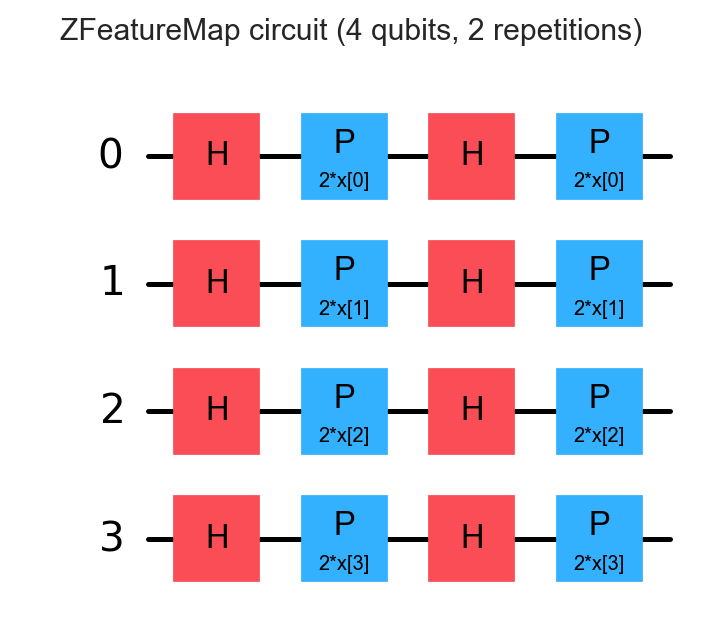

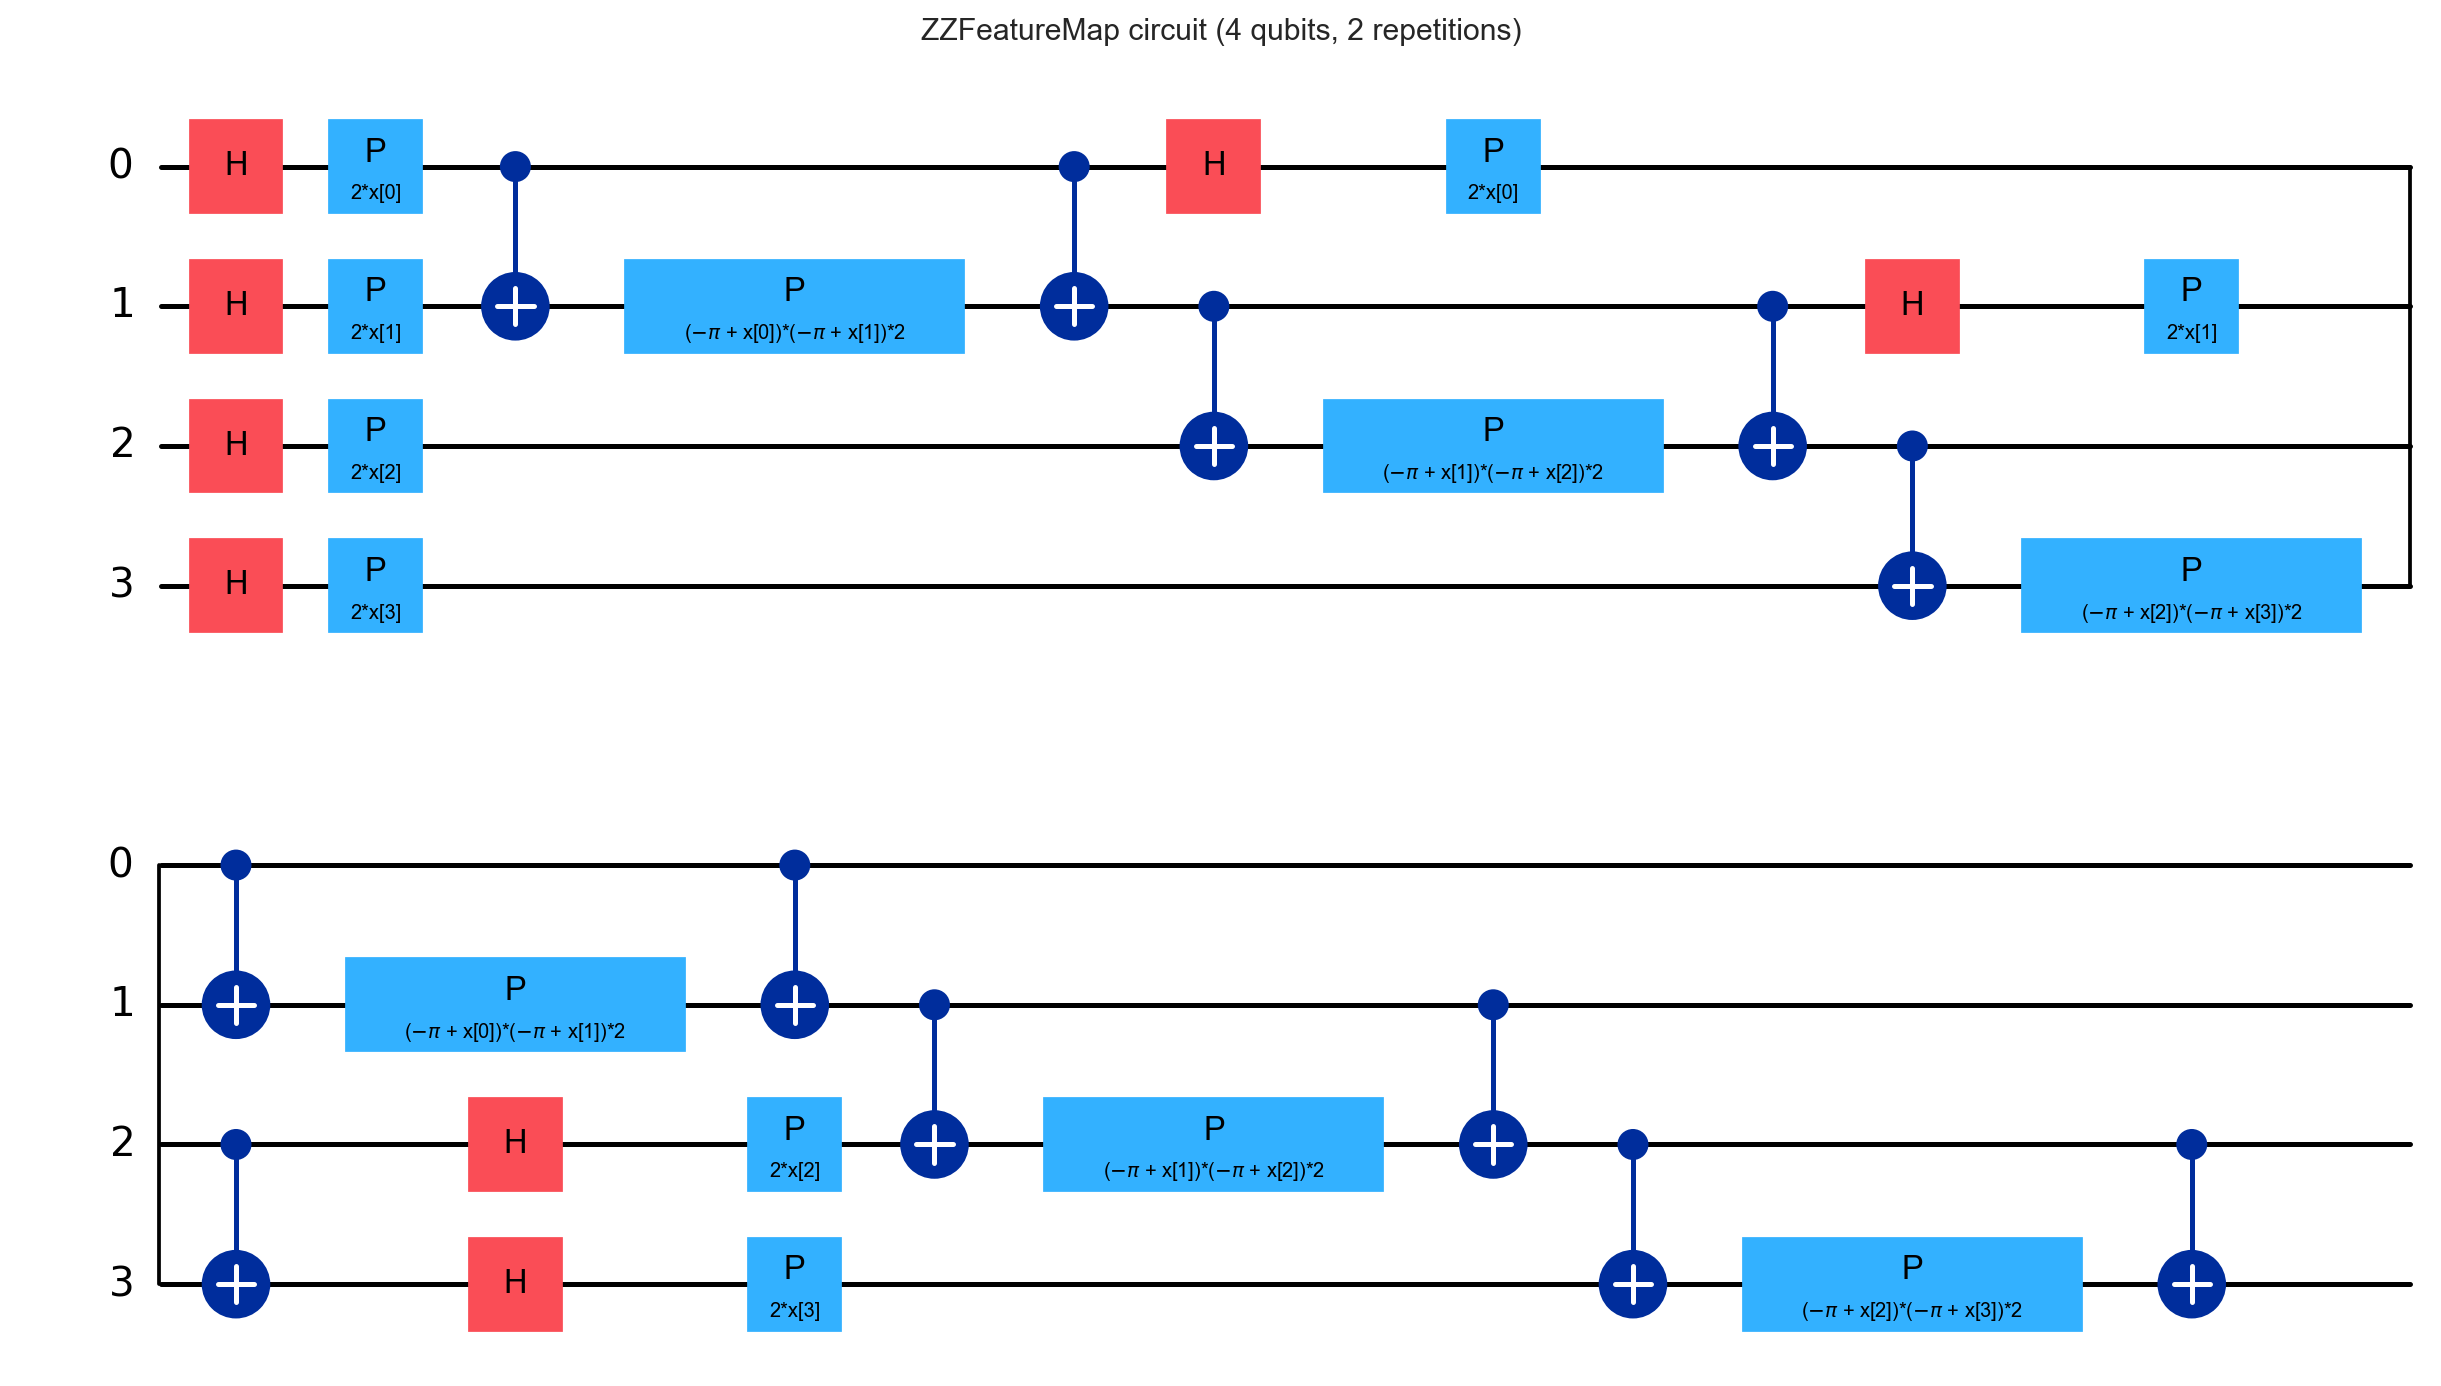

Loaded saved kernel matrices: Z_4q_reps2_none_seed42.npz
Loaded saved kernel matrices: ZZ_4q_reps2_linear_seed42.npz


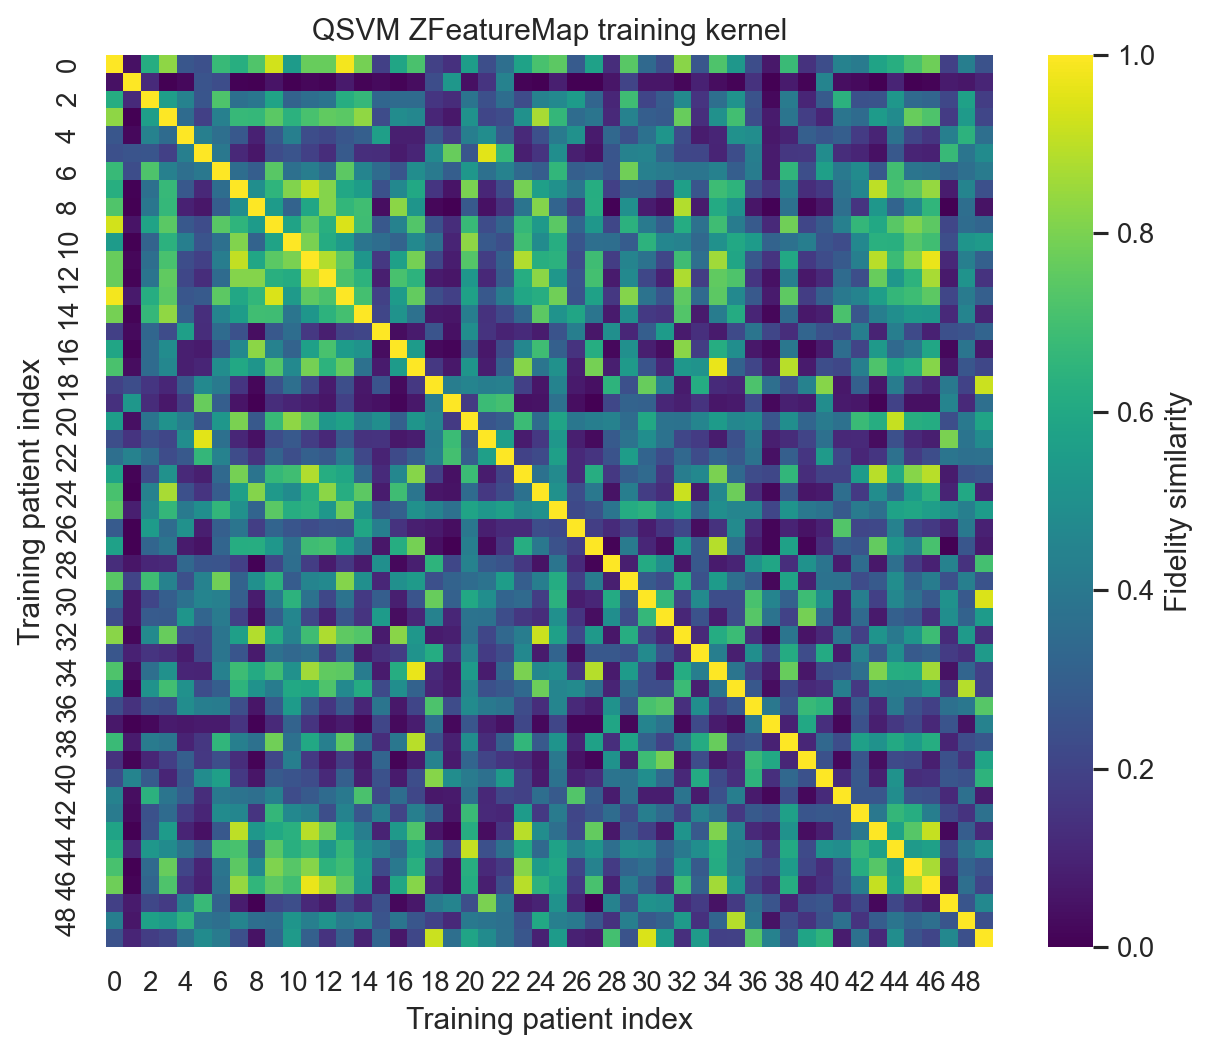

QSVM ZFeatureMap
  symmetric: True
  diagonal equals 1: True
  value range: 0.0 to 1.0
  shapes: (50, 50) and (114, 50)


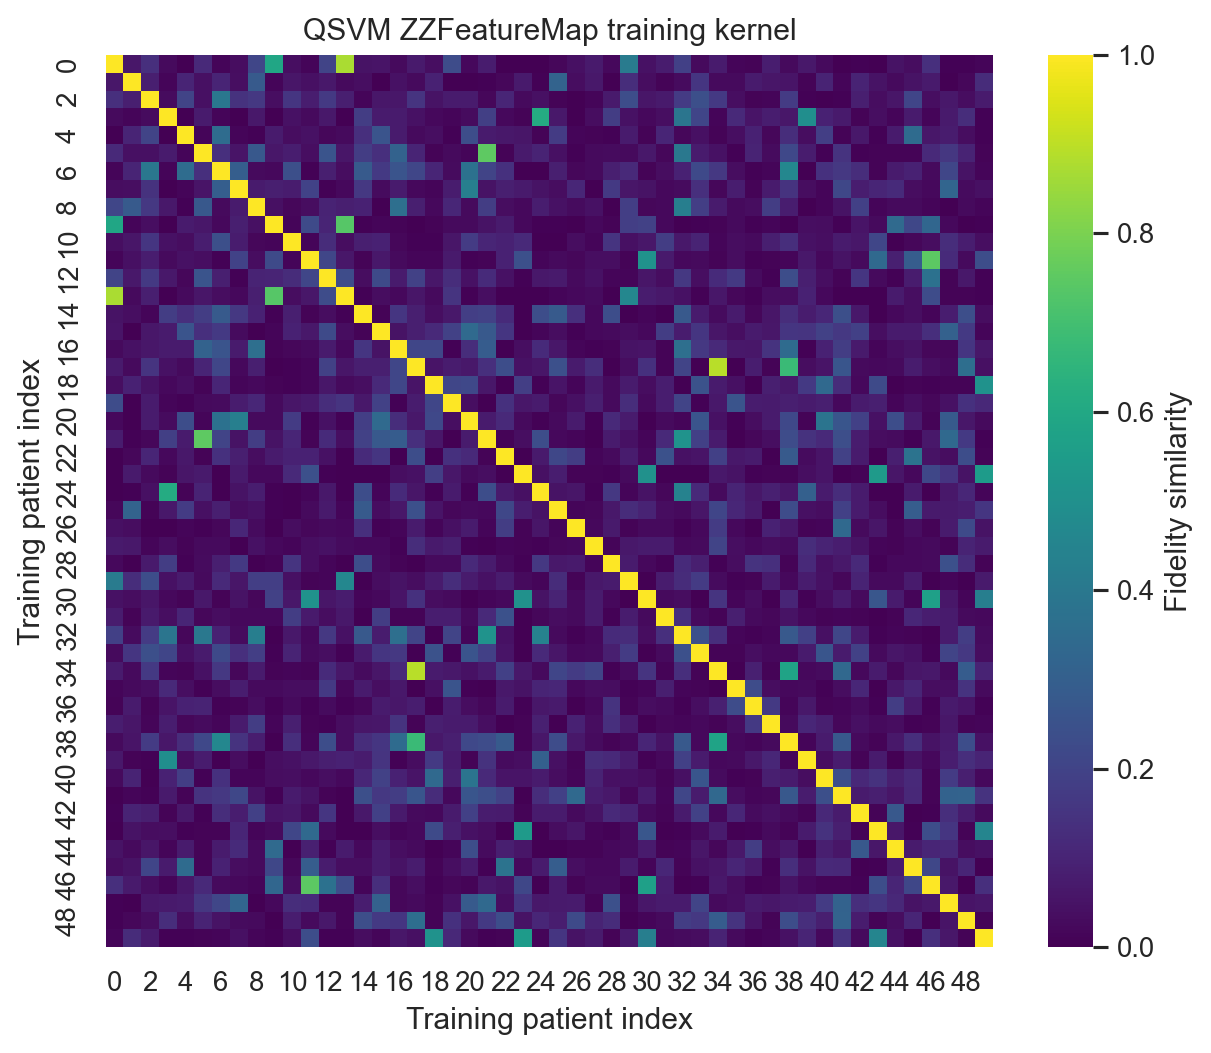

QSVM ZZFeatureMap
  symmetric: True
  diagonal equals 1: True
  value range: 0.0 to 1.0
  shapes: (50, 50) and (114, 50)


In [7]:
# Import the current Qiskit feature-map functions and quantum-kernel tools.
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from qiskit.circuit.library import z_feature_map as ZFeatureMap
from qiskit.circuit.library import zz_feature_map as ZZFeatureMap
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning import __version__ as qml_version
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute

# Print the installed Qiskit package versions.
print("qiskit:", qiskit_version, "| qiskit-aer:", aer_version, "| qiskit-machine-learning:", qml_version)

# Save the package versions so the setup is recorded beside the results.
package_versions = pd.DataFrame([
    {"package": "qiskit", "version": qiskit_version},
    {"package": "qiskit-aer", "version": aer_version},
    {"package": "qiskit-machine-learning", "version": qml_version},
    {"package": "scikit-learn", "version": sklearn.__version__},
    {"package": "numpy", "version": np.__version__},
    {"package": "pandas", "version": pd.__version__},
    {"package": "xgboost", "version": xgboost.__version__},
    {"package": "shap", "version": shap.__version__},
])
package_versions.to_csv(RESULTS_DIR / "package_versions.csv", index=False)

# Build the 4-qubit feature maps requested for the main comparison.
z_map_4 = ZFeatureMap(feature_dimension=4, reps=2)
zz_map_4 = ZZFeatureMap(feature_dimension=4, reps=2, entanglement="linear")

# Draw and save the two circuits so their gates can be inspected.
for map_name, feature_map, file_name in [
    ("ZFeatureMap", z_map_4, "05_z_feature_map_circuit.png"),
    ("ZZFeatureMap", zz_map_4, "06_zz_feature_map_circuit.png"),
]:
    circuit_figure = feature_map.draw(output="mpl", fold=16)
    circuit_figure.axes[0].set_title(map_name + " circuit (4 qubits, 2 repetitions)")
    save_figure(circuit_figure, RESULTS_DIR / file_name)

# Pick a small stratified sample of training patients for manageable simulation time.
quantum_train_positions, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=min(50, len(y_train)),
    random_state=RANDOM_SEED,
    stratify=y_train,
)
quantum_train_original_indices = train_indices[quantum_train_positions]
y_quantum_train = y_train.iloc[quantum_train_positions].to_numpy()
X_quantum_train_4 = quantum_features[4]["X_train"][quantum_train_positions]
X_quantum_test_4 = quantum_features[4]["X_test"]

# Save the sample counts that the report will use as its numeric source.
data_summary = pd.DataFrame([
    {"measure": "dataset source", "value": DATA_SOURCE},
    {"measure": "total patients", "value": len(y)},
    {"measure": "original features", "value": X.shape[1]},
    {"measure": "missing feature values", "value": int(X.isna().sum().sum())},
    {"measure": "benign patients", "value": int((y == 0).sum())},
    {"measure": "malignant patients", "value": int((y == 1).sum())},
    {"measure": "training patients", "value": len(y_train)},
    {"measure": "test patients", "value": len(y_test)},
    {"measure": "main QSVM training patients", "value": len(quantum_train_positions)},
    {"measure": "qubit-count experiment training patients", "value": 25},
])
data_summary.to_csv(RESULTS_DIR / "data_summary.csv", index=False)

# Compute a kernel pair once, or load it again when the same data and split are used.
def compute_kernel_matrices(cache_name, feature_map, X_train_angles, X_test_angles, train_row_ids, test_row_ids, seed):
    cache_path = KERNEL_DIR / (cache_name + ".npz")
    if cache_path.exists():
        saved = np.load(cache_path)
        saved_train_ids = saved["train_row_ids"]
        saved_test_ids = saved["test_row_ids"]
        saved_K_train = saved["K_train"]
        saved_K_test = saved["K_test"]
        saved_version = str(saved["cache_version"].item()) if "cache_version" in saved.files else "legacy"
        cache_is_valid = (
            saved_version == KERNEL_CACHE_VERSION
            and np.array_equal(saved_train_ids, train_row_ids)
            and np.array_equal(saved_test_ids, test_row_ids)
            and saved_K_train.shape == (len(train_row_ids), len(train_row_ids))
            and saved_K_test.shape == (len(test_row_ids), len(train_row_ids))
            and np.allclose(saved_K_train, saved_K_train.T, atol=1e-8)
            and np.allclose(np.diag(saved_K_train), 1.0, atol=1e-8)
            and saved_K_train.min() >= -1e-8
            and saved_K_train.max() <= 1.0 + 1e-8
            and saved_K_test.min() >= -1e-8
            and saved_K_test.max() <= 1.0 + 1e-8
        )
        if cache_is_valid:
            print("Loaded saved kernel matrices:", cache_path.name)
            saved_kernel_seconds = float(saved["kernel_seconds"])
            return saved_K_train, saved_K_test, saved_kernel_seconds
        print("Saved matrix failed checks and will be recomputed:", cache_path.name)

    # Use a seeded statevector sampler so the finite-shot kernel is repeatable.
    sampler = StatevectorSampler(default_shots=1024, seed=seed)
    fidelity = ComputeUncompute(sampler=sampler)
    quantum_kernel = FidelityQuantumKernel(feature_map=feature_map, fidelity=fidelity, enforce_psd=False)

    # Compute train-versus-train and test-versus-train similarities.
    start_time = time.time()
    K_train = quantum_kernel.evaluate(x_vec=X_train_angles)
    K_test = quantum_kernel.evaluate(x_vec=X_test_angles, y_vec=X_train_angles)
    elapsed_seconds = time.time() - start_time

    # Save both matrices and the row IDs that identify their split.
    np.savez_compressed(
        cache_path,
        K_train=K_train,
        K_test=K_test,
        train_row_ids=train_row_ids,
        test_row_ids=test_row_ids,
        kernel_seconds=elapsed_seconds,
        cache_version=np.array(KERNEL_CACHE_VERSION),
    )
    print("Computed and saved:", cache_path.name, "in", round(elapsed_seconds, 2), "seconds")
    return K_train, K_test, elapsed_seconds

# Compute the two main 4-qubit kernel pairs.
main_kernel_matrices = {}
main_kernel_matrices["QSVM ZFeatureMap"] = compute_kernel_matrices(
    "Z_4q_reps2_none_seed42",
    z_map_4,
    X_quantum_train_4,
    X_quantum_test_4,
    quantum_train_original_indices,
    test_indices,
    RANDOM_SEED,
)
main_kernel_matrices["QSVM ZZFeatureMap"] = compute_kernel_matrices(
    "ZZ_4q_reps2_linear_seed42",
    zz_map_4,
    X_quantum_train_4,
    X_quantum_test_4,
    quantum_train_original_indices,
    test_indices,
    RANDOM_SEED,
)

# Plot both training kernel matrices as readable heatmaps.
for model_name, (K_train, K_test, elapsed_seconds) in main_kernel_matrices.items():
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(K_train, cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Fidelity similarity"})
    ax.set_title(model_name + " training kernel")
    ax.set_xlabel("Training patient index")
    ax.set_ylabel("Training patient index")
    save_figure(fig, RESULTS_DIR / (model_name.lower().replace(" ", "_") + "_kernel_heatmap.png"))

    # Print the requested symmetry, diagonal, and value-range checks.
    print(model_name)
    print("  symmetric:", bool(np.allclose(K_train, K_train.T, atol=1e-8)))
    print("  diagonal equals 1:", bool(np.allclose(np.diag(K_train), 1.0, atol=1e-8)))
    print("  value range:", round(float(K_train.min()), 4), "to", round(float(K_train.max()), 4))
    print("  shapes:", K_train.shape, "and", K_test.shape)

## Step 6: Train and test the QSVM

We give the saved kernel matrix to a standard SVM with a precomputed kernel. The penalty `C` is selected from `[0.1, 1, 10, 100]` using stratified 5-fold cross-validation on the quantum training sample. Malignant recall is important because a missed malignant case is the most serious classification error in this exercise.

QSVM ZFeatureMap | best C: 1 | test scores: {'accuracy': 0.8947368421052632, 'precision': 0.9411764705882353, 'recall': 0.7619047619047619, 'f1': 0.8421052631578947, 'roc_auc': 0.976521164021164}


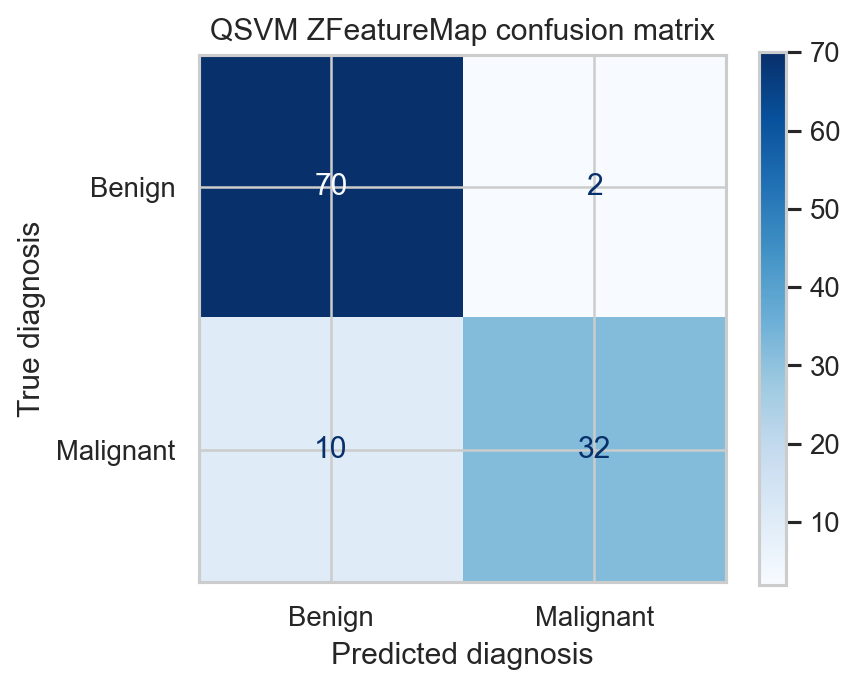

QSVM ZZFeatureMap | best C: 10 | test scores: {'accuracy': 0.7368421052631579, 'precision': 0.7, 'recall': 0.5, 'f1': 0.5833333333333334, 'roc_auc': 0.7840608465608466}


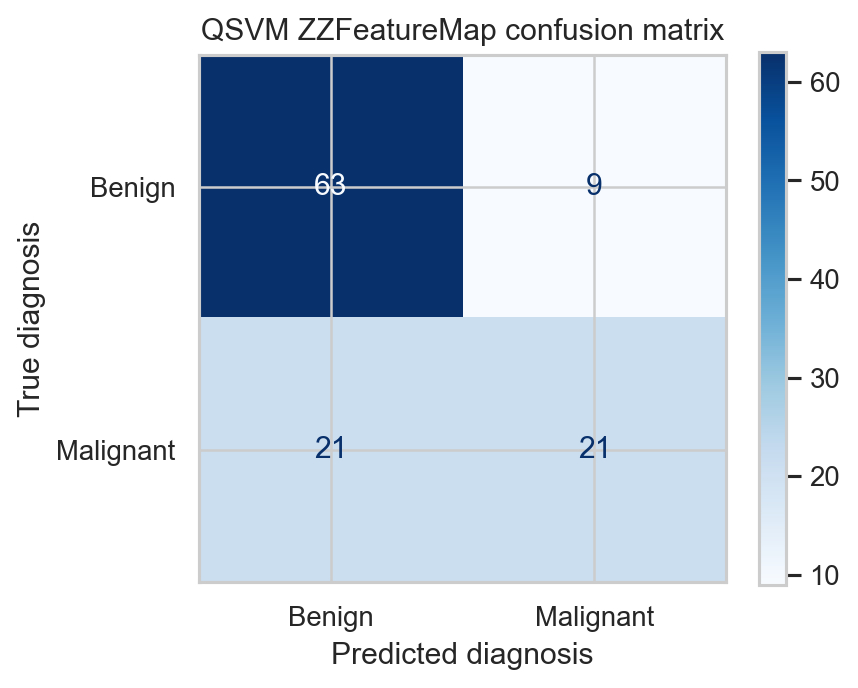

,model,features_used,n_qubits,reps,entanglement,accuracy,precision,recall,f1,roc_auc,best_C,cv_f1,kernel_time_s,training_time_s
0,QSVM ZFeatureMap,4 PCA components; 50 quantum training patients,4,2,none,0.894737,0.941176,0.761905,0.842105,0.976521,1,0.854762,55.130000,55.185396
1,QSVM ZZFeatureMap,4 PCA components; 50 quantum training patients,4,2,linear,0.736842,0.700000,0.500000,0.583333,0.784061,10,0.502222,74.203913,74.265843


In [8]:
# Tune C and evaluate one precomputed-kernel SVM.
def train_qsvm_from_matrices(K_train, K_test, y_train_values, y_test_values, seed):
    qsvm_search = GridSearchCV(
        SVC(kernel="precomputed"),
        {"C": [0.1, 1, 10, 100]},
        scoring="f1",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
        n_jobs=1,
        refit=True,
    )
    start_time = time.time()
    qsvm_search.fit(K_train, y_train_values)
    fit_seconds = time.time() - start_time

    # Predict labels and signed SVM scores for the held out patients.
    y_prediction = qsvm_search.predict(K_test)
    y_score = qsvm_search.decision_function(K_test)
    scores = classification_metrics(y_test_values, y_prediction, y_score)
    return qsvm_search, y_prediction, y_score, scores, fit_seconds

# Fit the Z and ZZ QSVMs using their saved matrices.
quantum_model_results = {}
for model_name, matrices in main_kernel_matrices.items():
    K_train, K_test, kernel_seconds = matrices
    qsvm_search, y_prediction, y_score, scores, fit_seconds = train_qsvm_from_matrices(
        K_train,
        K_test,
        y_quantum_train,
        y_test.to_numpy(),
        RANDOM_SEED,
    )
    quantum_model_results[model_name] = {
        "model": model_name,
        "features_used": "4 PCA components; 50 quantum training patients",
        "n_qubits": 4,
        "reps": 2,
        "entanglement": "none" if model_name == "QSVM ZFeatureMap" else "linear",
        **scores,
        "best_C": qsvm_search.best_params_["C"],
        "cv_f1": qsvm_search.best_score_,
        "kernel_time_s": kernel_seconds,
        "training_time_s": kernel_seconds + fit_seconds,
        "search": qsvm_search,
        "y_pred": y_prediction,
        "y_score": y_score,
        "K_train": K_train,
        "K_test": K_test,
    }
    print(model_name, "| best C:", qsvm_search.best_params_["C"], "| test scores:", scores)

    # Save the confusion matrix for this feature map.
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_prediction,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=ax,
        colorbar=True,
    )
    ax.set_title(model_name + " confusion matrix")
    ax.set_xlabel("Predicted diagnosis")
    ax.set_ylabel("True diagnosis")
    save_figure(fig, RESULTS_DIR / (model_name.lower().replace(" ", "_") + "_confusion_matrix.png"))

# Save the main QSVM results table.
main_qsvm_rows = [
    {key: value for key, value in result.items() if key not in {"search", "y_pred", "y_score", "K_train", "K_test"}}
    for result in quantum_model_results.values()
]
main_qsvm_results = pd.DataFrame(main_qsvm_rows)
main_qsvm_results.to_csv(RESULTS_DIR / "main_qsvm_results.csv", index=False)
display(main_qsvm_results)

## Step 7: Small quantum and model comparisons

We keep each extra run on the same 50 quantum training patients and held out test set. We compare the two maps, three repetition counts, two ZZ entanglement patterns, and 4/6/8 qubits. The results below include the SVM with an ordinary RBF kernel and the classical baselines.

Loaded saved kernel matrices: ZZ_4q_reps1_linear_seed42.npz


QSVM ZZ reps 1 | F1: 0.762 | recall: 0.762
Loaded saved kernel matrices: ZZ_4q_reps3_linear_seed42.npz
QSVM ZZ reps 3 | F1: 0.556 | recall: 0.595
Loaded saved kernel matrices: ZZ_4q_reps2_full_seed42.npz
QSVM ZZ full entanglement | F1: 0.471 | recall: 0.381
Loaded saved kernel matrices: ZZ_4q_reps2_linear_seed42_train25.npz


QSVM ZZ 4 qubits (25 training) | F1: 0.433 | recall: 0.31
Loaded saved kernel matrices: ZZ_6q_reps2_linear_seed42_train25.npz


QSVM ZZ 6 qubits (25 training) | F1: 0.0 | recall: 0.0
Loaded saved kernel matrices: ZZ_8q_reps2_linear_seed42_train25.npz
QSVM ZZ 8 qubits (25 training) | F1: 0.0 | recall: 0.0


,configuration,accuracy,precision,recall,f1,roc_auc
0,QSVM ZFeatureMap,0.894737,0.941176,0.761905,0.842105,0.976521
1,QSVM ZZFeatureMap,0.736842,0.700000,0.500000,0.583333,0.784061


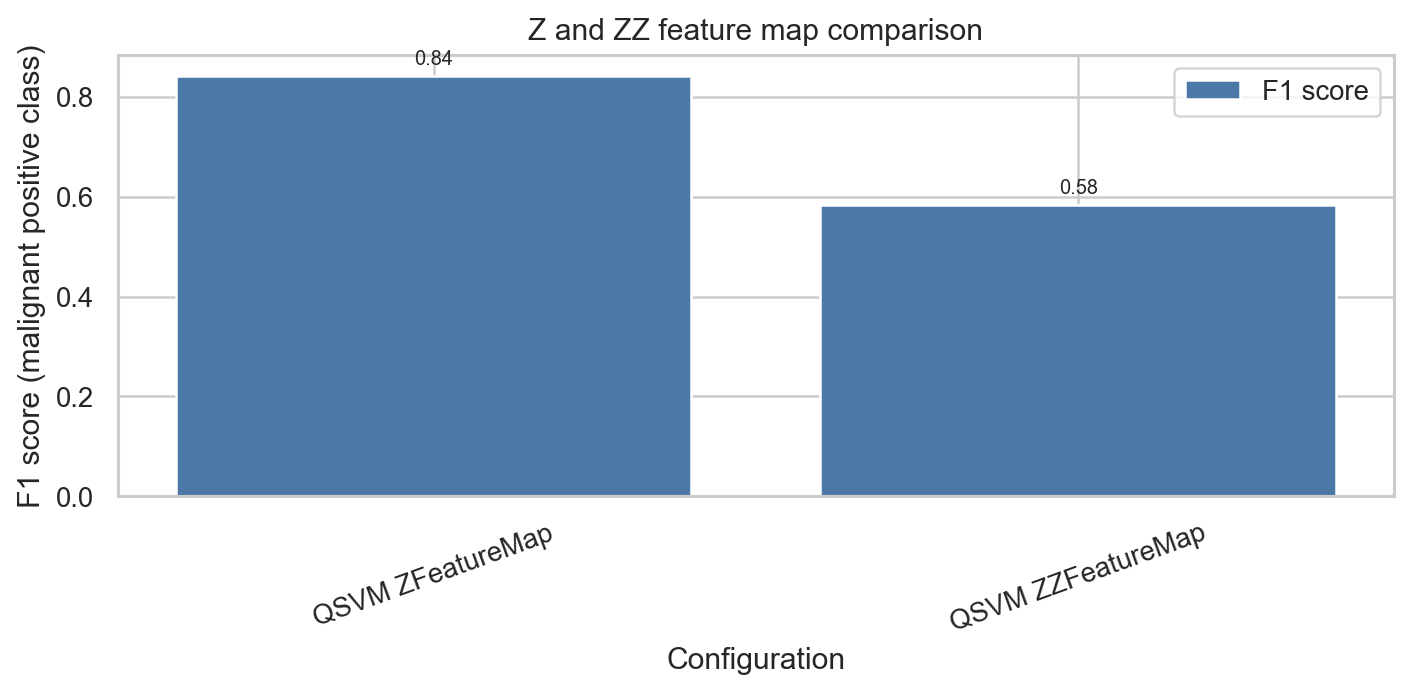

,configuration,accuracy,precision,recall,f1,roc_auc
0,QSVM ZZ reps 1,0.824561,0.761905,0.761905,0.761905,0.880952
1,QSVM ZZFeatureMap,0.736842,0.700000,0.500000,0.583333,0.784061
2,QSVM ZZ reps 3,0.649123,0.520833,0.595238,0.555556,0.667328


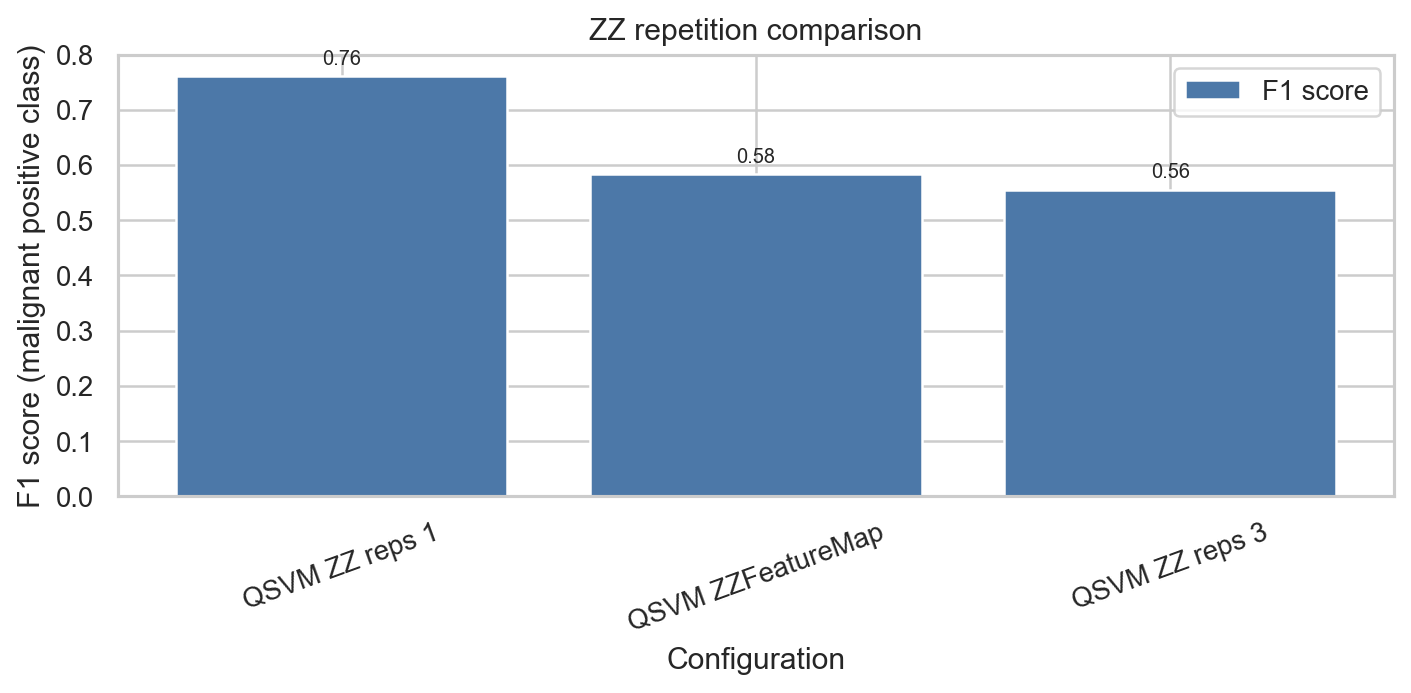

,configuration,accuracy,precision,recall,f1,roc_auc
0,QSVM ZZFeatureMap,0.736842,0.700000,0.500000,0.583333,0.784061
1,QSVM ZZ full entanglement,0.684211,0.615385,0.380952,0.470588,0.730820


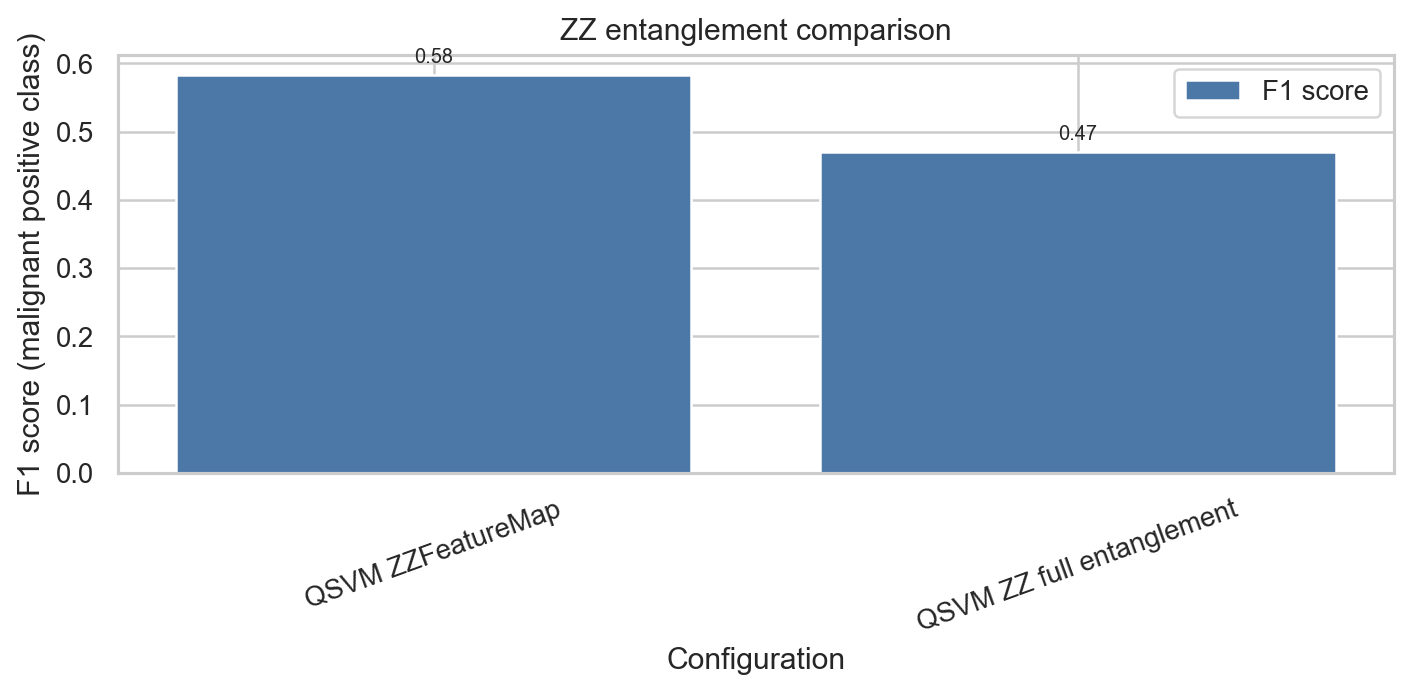

,configuration,accuracy,precision,recall,f1,roc_auc
0,QSVM ZZ 4 qubits (25 training),0.701754,0.722222,0.309524,0.433333,0.757937
1,QSVM ZZ 6 qubits (25 training),0.631579,0.000000,0.000000,0.000000,0.602183
2,QSVM ZZ 8 qubits (25 training),0.631579,0.000000,0.000000,0.000000,0.601521


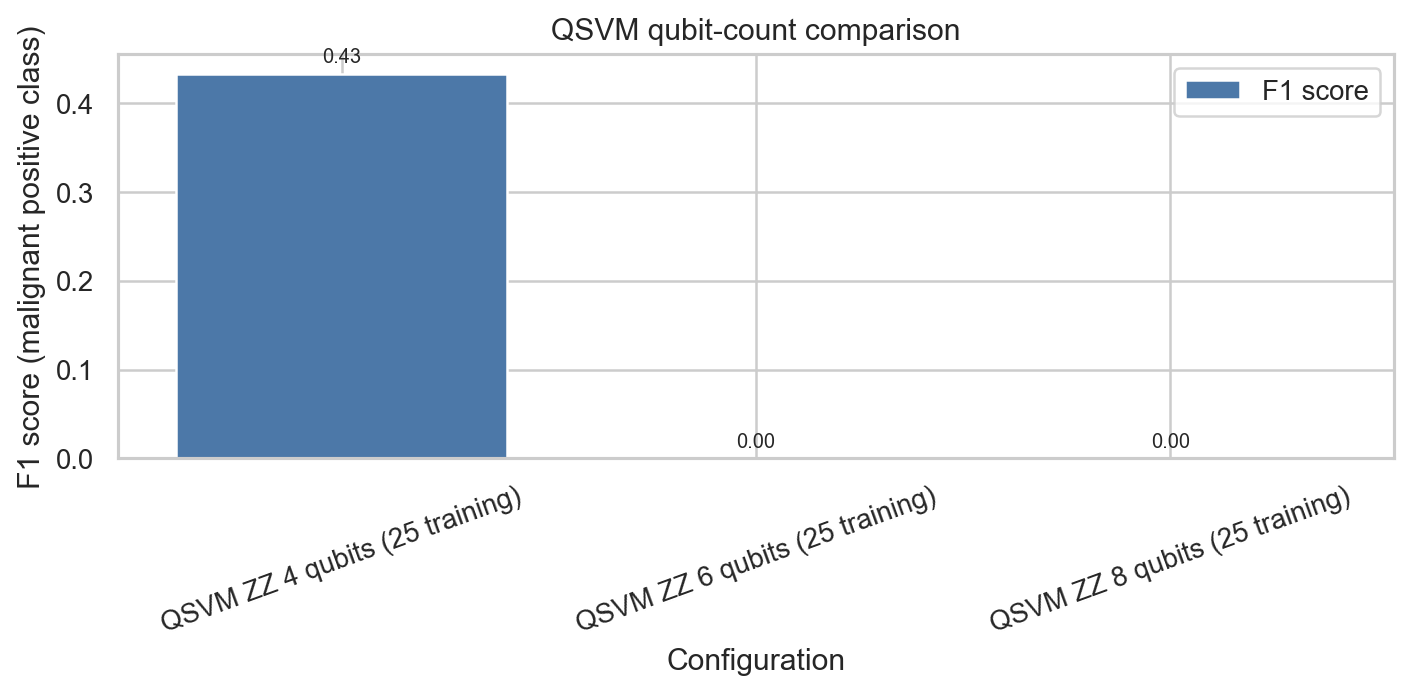

,configuration,accuracy,precision,recall,f1,roc_auc
0,SVM (RBF),0.947368,0.973684,0.880952,0.925000,0.996693
1,QSVM ZFeatureMap,0.894737,0.941176,0.761905,0.842105,0.976521
2,QSVM ZZFeatureMap,0.736842,0.700000,0.500000,0.583333,0.784061


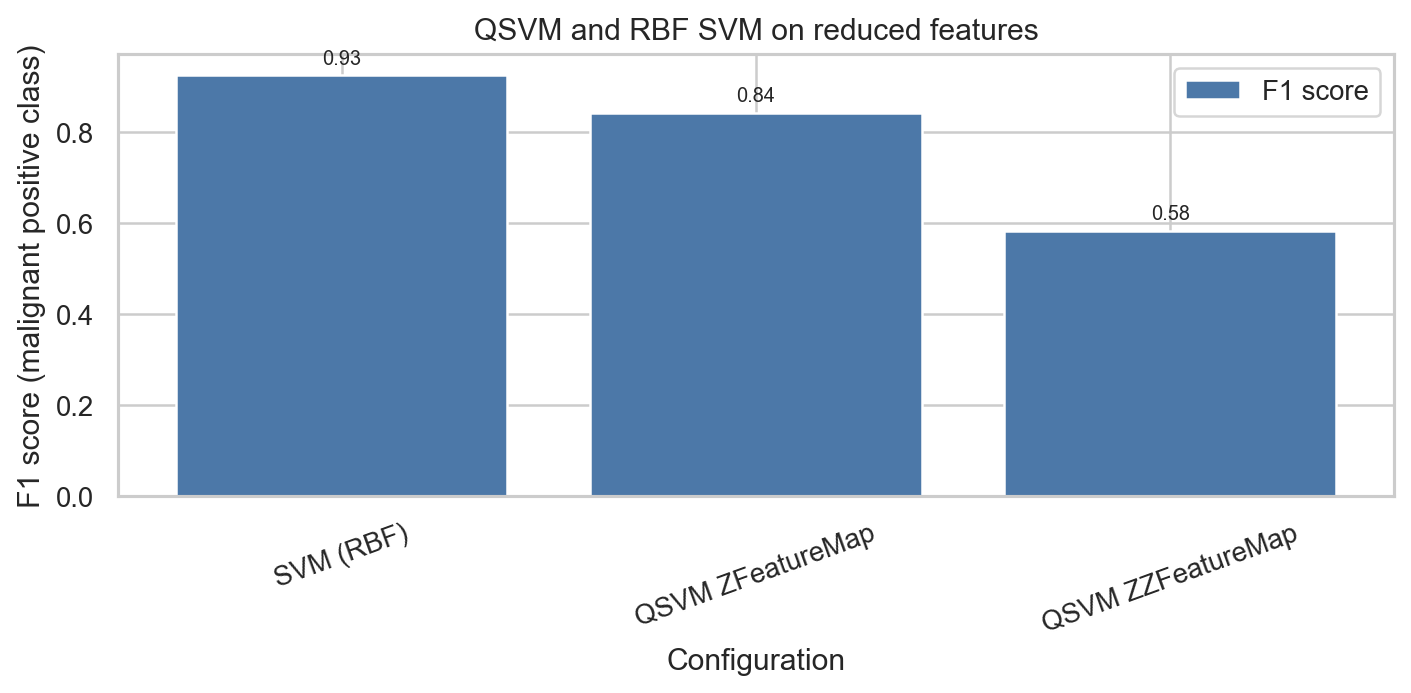

,configuration,accuracy,precision,recall,f1,roc_auc
0,SVM (linear) (All 30 features),0.982456,1.000000,0.952381,0.975610,0.996362
1,Random Forest (All 30 features),0.973684,1.000000,0.928571,0.962963,0.992890
2,SVM (RBF) (All 30 features),0.973684,1.000000,0.928571,0.962963,0.992725
3,Logistic Regression (All 30 features),0.964912,0.975000,0.928571,0.951220,0.996032
4,XGBoost (All 30 features),0.964912,1.000000,0.904762,0.950000,0.994048
5,Decision Tree (All 30 features),0.929825,0.904762,0.904762,0.904762,0.924603
6,Naive Bayes (All 30 features),0.921053,0.923077,0.857143,0.888889,0.989087
7,Logistic Regression (PCA 4 components),0.973684,1.000000,0.928571,0.962963,0.998016
8,SVM (linear) (PCA 4 components),0.973684,1.000000,0.928571,0.962963,0.997685
9,Random Forest (PCA 4 components),0.956140,0.974359,0.904762,0.938272,0.993882


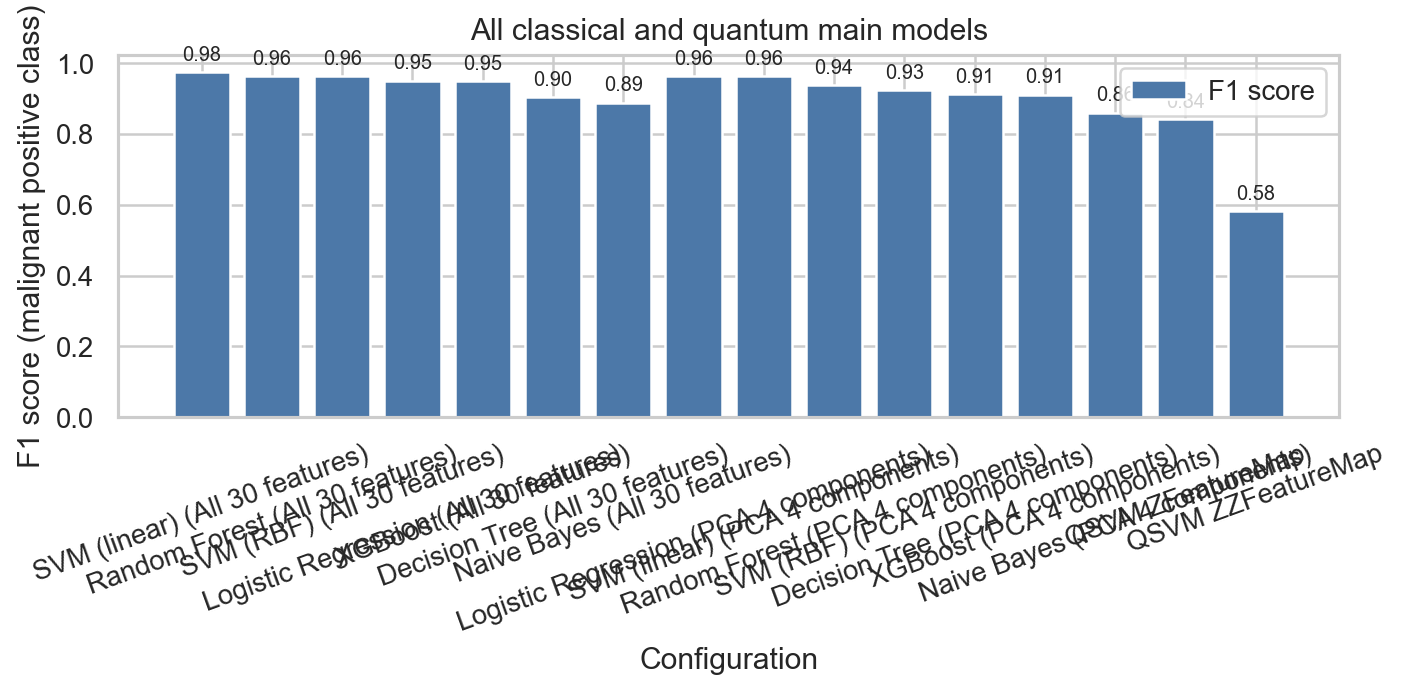

In [9]:
# Make the requested feature map for a selected width and circuit setting.
def make_feature_map(map_kind, qubit_count, reps, entanglement):
    if map_kind == "Z":
        return ZFeatureMap(feature_dimension=qubit_count, reps=reps)
    return ZZFeatureMap(feature_dimension=qubit_count, reps=reps, entanglement=entanglement)

# Run a new quantum setting and save its kernel pair for later runs.
def run_qsvm_configuration(map_kind, qubit_count, reps, entanglement, display_name, train_sample_size=50):
    feature_map = make_feature_map(map_kind, qubit_count, reps, entanglement)
    map_suffix = entanglement if map_kind == "ZZ" else "none"
    cache_name = f"{map_kind}_{qubit_count}q_reps{reps}_{map_suffix}_seed42"
    if train_sample_size == 50:
        sample_positions = quantum_train_positions
    else:
        sample_positions, _ = train_test_split(
            np.arange(len(y_train)),
            train_size=min(train_sample_size, len(y_train)),
            random_state=RANDOM_SEED,
            stratify=y_train,
        )
        cache_name += f"_train{train_sample_size}"
    sample_original_indices = train_indices[sample_positions]
    sample_y_train = y_train.iloc[sample_positions].to_numpy()
    X_train_angles = quantum_features[qubit_count]["X_train"][sample_positions]
    X_test_angles = quantum_features[qubit_count]["X_test"]
    matrices = compute_kernel_matrices(
        cache_name,
        feature_map,
        X_train_angles,
        X_test_angles,
        sample_original_indices,
        test_indices,
        RANDOM_SEED,
    )
    K_train, K_test, kernel_seconds = matrices
    search, y_prediction, y_score, scores, fit_seconds = train_qsvm_from_matrices(
        K_train,
        K_test,
        sample_y_train,
        y_test.to_numpy(),
        RANDOM_SEED,
    )
    result = {
        "model": display_name,
        "features_used": f"{qubit_count} PCA components; {len(sample_positions)} quantum training patients",
        "n_qubits": qubit_count,
        "reps": reps,
        "entanglement": map_suffix,
        **scores,
        "best_C": search.best_params_["C"],
        "cv_f1": search.best_score_,
        "kernel_time_s": kernel_seconds,
        "training_time_s": kernel_seconds + fit_seconds,
        "search": search,
        "y_pred": y_prediction,
        "y_score": y_score,
        "K_train": K_train,
        "K_test": K_test,
    }
    quantum_model_results[display_name] = result
    print(display_name, "| F1:", round(scores["f1"], 3), "| recall:", round(scores["recall"], 3))
    return result

# Change circuit repetition count while keeping width and entanglement fixed.
reps_one = run_qsvm_configuration("ZZ", 4, 1, "linear", "QSVM ZZ reps 1")
reps_three = run_qsvm_configuration("ZZ", 4, 3, "linear", "QSVM ZZ reps 3")

# Change only the entanglement pattern for the 4-qubit ZZ map.
entanglement_full = run_qsvm_configuration("ZZ", 4, 2, "full", "QSVM ZZ full entanglement")

# Change the number of PCA components and qubits.
qubits_four_25 = run_qsvm_configuration("ZZ", 4, 2, "linear", "QSVM ZZ 4 qubits (25 training)", train_sample_size=25)
qubits_six = run_qsvm_configuration("ZZ", 6, 2, "linear", "QSVM ZZ 6 qubits (25 training)", train_sample_size=25)
qubits_eight = run_qsvm_configuration("ZZ", 8, 2, "linear", "QSVM ZZ 8 qubits (25 training)", train_sample_size=25)

# Make small experiment tables from the main maps and additional configurations.
feature_map_table = pd.DataFrame([
    {key: value for key, value in quantum_model_results[name].items() if key not in {"search", "y_pred", "y_score", "K_train", "K_test"}}
    for name in ["QSVM ZFeatureMap", "QSVM ZZFeatureMap"]
]).rename(columns={"model": "configuration"})
reps_table = pd.DataFrame([
    {key: value for key, value in quantum_model_results[name].items() if key not in {"search", "y_pred", "y_score", "K_train", "K_test"}}
    for name in ["QSVM ZZ reps 1", "QSVM ZZFeatureMap", "QSVM ZZ reps 3"]
]).rename(columns={"model": "configuration"})
entanglement_table = pd.DataFrame([
    {key: value for key, value in quantum_model_results[name].items() if key not in {"search", "y_pred", "y_score", "K_train", "K_test"}}
    for name in ["QSVM ZZFeatureMap", "QSVM ZZ full entanglement"]
]).rename(columns={"model": "configuration"})
qubit_table = pd.DataFrame([
    {key: value for key, value in quantum_model_results[name].items() if key not in {"search", "y_pred", "y_score", "K_train", "K_test"}}
    for name in ["QSVM ZZ 4 qubits (25 training)", "QSVM ZZ 6 qubits (25 training)", "QSVM ZZ 8 qubits (25 training)"]
]).rename(columns={"model": "configuration"})

# Save each experiment table as a CSV file.
feature_map_table.to_csv(RESULTS_DIR / "experiment_feature_maps.csv", index=False)
reps_table.to_csv(RESULTS_DIR / "experiment_repetitions.csv", index=False)
entanglement_table.to_csv(RESULTS_DIR / "experiment_entanglement.csv", index=False)
qubit_table.to_csv(RESULTS_DIR / "experiment_qubits.csv", index=False)

# Draw and save a small F1 chart for one experiment table.
def save_f1_chart(table, title, file_name):
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(table["configuration"], table["f1"], color="#4C78A8", label="F1 score")
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Configuration")
    ax.set_ylabel("F1 score (malignant positive class)")
    ax.tick_params(axis="x", labelrotation=20)
    ax.legend(handles=[bars], labels=["F1 score"])
    save_figure(fig, RESULTS_DIR / file_name)

# Show each compact table and its matching chart.
for table, title, file_name in [
    (feature_map_table, "Z and ZZ feature map comparison", "experiment_feature_maps.png"),
    (reps_table, "ZZ repetition comparison", "experiment_repetitions.png"),
    (entanglement_table, "ZZ entanglement comparison", "experiment_entanglement.png"),
    (qubit_table, "QSVM qubit-count comparison", "experiment_qubits.png"),
]:
    display(table[["configuration", "accuracy", "precision", "recall", "f1", "roc_auc"]])
    save_f1_chart(table, title, file_name)

# Compare both QSVM maps with the RBF SVM on the same four PCA components.
rbf_reduced = classical_results[
    (classical_results["model"] == "SVM (RBF)")
    & (classical_results["features_used"] == "PCA 4 components")
].iloc[0]
qsvm_vs_rbf_table = pd.concat([
    pd.DataFrame([rbf_reduced.to_dict()]).rename(columns={"model": "configuration"}),
    feature_map_table,
], ignore_index=True, sort=False)
qsvm_vs_rbf_table.to_csv(RESULTS_DIR / "experiment_qsvm_vs_rbf.csv", index=False)
display(qsvm_vs_rbf_table[["configuration", "accuracy", "precision", "recall", "f1", "roc_auc"]])
save_f1_chart(qsvm_vs_rbf_table, "QSVM and RBF SVM on reduced features", "experiment_qsvm_vs_rbf.png")

# Compare the two QSVMs with every classical baseline in the main results.
all_model_rows = []
for _, result_row in classical_results.iterrows():
    all_model_rows.append({**result_row.to_dict(), "configuration": result_row["model"] + " (" + result_row["features_used"] + ")"})
for _, result_row in feature_map_table.iterrows():
    all_model_rows.append(result_row.to_dict())
all_models_table = pd.DataFrame(all_model_rows)
all_models_table.to_csv(RESULTS_DIR / "experiment_all_models.csv", index=False)
display(all_models_table[["configuration", "accuracy", "precision", "recall", "f1", "roc_auc"]])
save_f1_chart(all_models_table, "All classical and quantum main models", "experiment_all_models.png")

### Stability across five random splits

We repeat the final comparison on five stratified splits. To keep the repeated circuit work bounded, the QSVMs again use 50 training patients per split. The classical finalists use their full training split. We report mean and standard deviation for each metric.

Loaded saved kernel matrices: stability_Z_4q_reps2_none_seed7.npz
stability 7 QSVM ZFeatureMap F1: 0.833
Loaded saved kernel matrices: stability_ZZ_4q_reps2_linear_seed7.npz
stability 7 QSVM ZZFeatureMap F1: 0.464


Loaded saved kernel matrices: stability_Z_4q_reps2_none_seed21.npz
stability 21 QSVM ZFeatureMap F1: 0.886
Loaded saved kernel matrices: stability_ZZ_4q_reps2_linear_seed21.npz
stability 21 QSVM ZZFeatureMap F1: 0.506


Loaded saved kernel matrices: stability_Z_4q_reps2_none_seed84.npz
stability 84 QSVM ZFeatureMap F1: 0.878
Loaded saved kernel matrices: stability_ZZ_4q_reps2_linear_seed84.npz
stability 84 QSVM ZZFeatureMap F1: 0.506


Loaded saved kernel matrices: stability_Z_4q_reps2_none_seed123.npz
stability 123 QSVM ZFeatureMap F1: 0.909
Loaded saved kernel matrices: stability_ZZ_4q_reps2_linear_seed123.npz
stability 123 QSVM ZZFeatureMap F1: 0.554


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,QSVM ZFeatureMap,0.907018,0.021126,0.898004,0.047847,0.847619,0.068595,0.869731,0.031518,0.959259,0.021319
1,QSVM ZZFeatureMap,0.680702,0.032586,0.586930,0.066698,0.476190,0.060703,0.522795,0.046580,0.700198,0.053293
2,SVM (RBF) (PCA 4 components),0.945614,0.011437,0.947104,0.034840,0.904762,0.037646,0.924514,0.016183,0.989418,0.006647
3,SVM (linear) (All 30 features),0.970175,0.014678,0.975936,0.024160,0.942857,0.036109,0.958667,0.020733,0.993915,0.005158


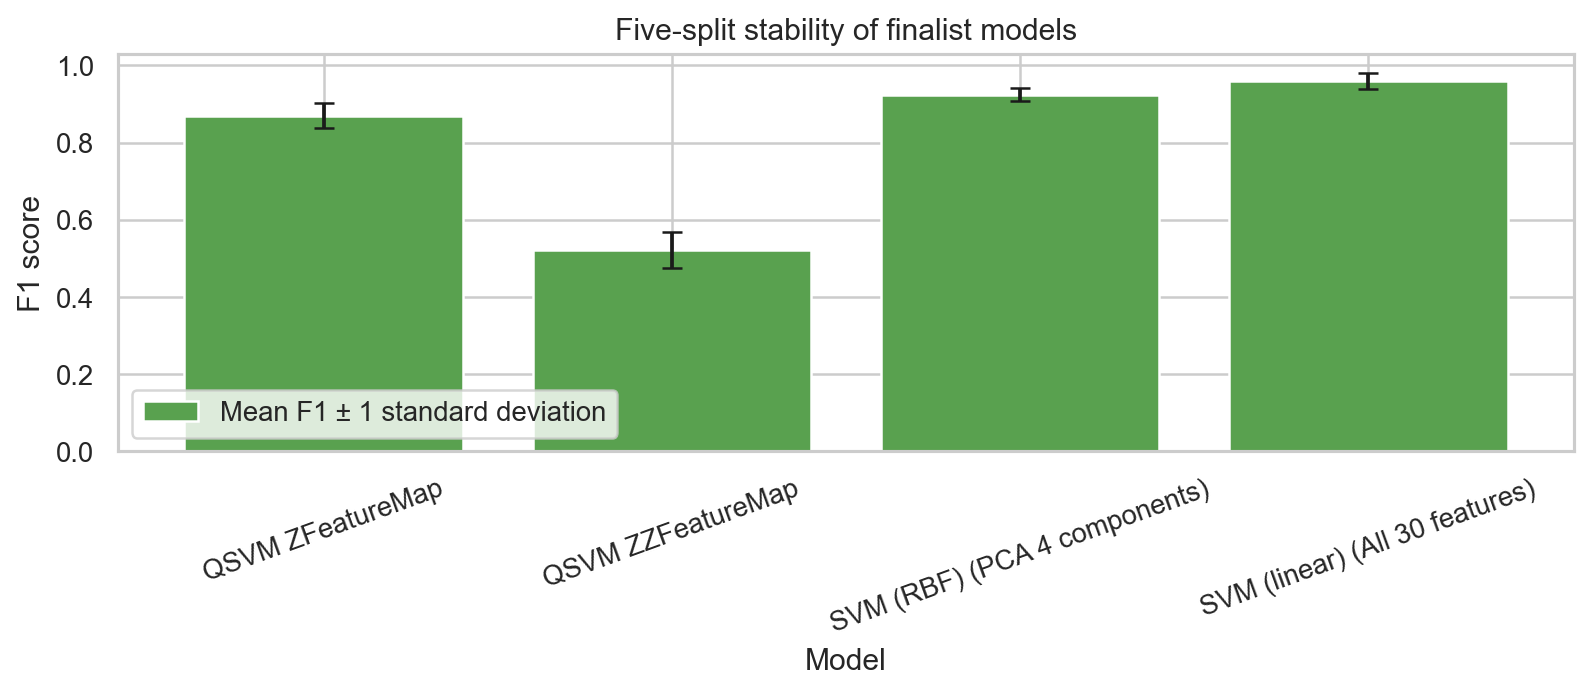

In [10]:
# Select the main classical F1 leader and include the reduced-feature RBF baseline.
best_classical_row = classical_results.sort_values("f1", ascending=False).iloc[0]
best_classical_key = (best_classical_row["model"], best_classical_row["features_used"])
stability_classical_keys = [best_classical_key]
rbf_key = ("SVM (RBF)", "PCA 4 components")
if rbf_key not in stability_classical_keys:
    stability_classical_keys.append(rbf_key)

# Use five clearly listed seeds for the repeated split check.
stability_seeds = [42, 7, 21, 84, 123]
stability_rows = []

# Repeat the selected classical models and the two main quantum maps.
for split_seed in stability_seeds:
    split_train_ids, split_test_ids = train_test_split(
        all_row_numbers,
        test_size=0.20,
        random_state=split_seed,
        stratify=y,
    )
    X_train_seed = X.iloc[split_train_ids].reset_index(drop=True)
    X_test_seed = X.iloc[split_test_ids].reset_index(drop=True)
    y_train_seed = y.iloc[split_train_ids].reset_index(drop=True)
    y_test_seed = y.iloc[split_test_ids].reset_index(drop=True)

    # Fit the finalist baseline pipelines using only this split's training rows.
    for model_name, feature_set in stability_classical_keys:
        if split_seed == RANDOM_SEED:
            saved = classical_predictions[(model_name, feature_set)]
            y_prediction_seed = saved["y_pred"]
            y_score_seed = saved["y_score"]
        else:
            estimator, parameter_grid = get_model_specs(split_seed)[model_name]
            use_pca = feature_set == "PCA 4 components"
            seed_search = GridSearchCV(
                make_classical_pipeline(estimator, use_pca),
                parameter_grid,
                scoring="f1",
                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed),
                n_jobs=1,
                refit=True,
            )
            seed_search.fit(X_train_seed, y_train_seed)
            y_prediction_seed = seed_search.predict(X_test_seed)
            if hasattr(seed_search.best_estimator_, "decision_function"):
                y_score_seed = seed_search.decision_function(X_test_seed)
            else:
                y_score_seed = seed_search.predict_proba(X_test_seed)[:, 1]
        seed_scores = classification_metrics(y_test_seed, y_prediction_seed, y_score_seed)
        stability_rows.append({
            "seed": split_seed,
            "model": model_name + " (" + feature_set + ")",
            **seed_scores,
        })

    # Reuse the training-only PCA pattern and angle scaling for this split.
    if split_seed == RANDOM_SEED:
        split_X_train_angles = quantum_features[4]["X_train"]
        split_X_test_angles = quantum_features[4]["X_test"]
    else:
        split_scaler = StandardScaler()
        split_X_train_scaled = split_scaler.fit_transform(X_train_seed)
        split_X_test_scaled = split_scaler.transform(X_test_seed)
        split_pca = PCA(n_components=4, random_state=split_seed)
        split_X_train_pca = split_pca.fit_transform(split_X_train_scaled)
        split_X_test_pca = split_pca.transform(split_X_test_scaled)
        split_angle_scaler = MinMaxScaler(feature_range=(0, np.pi))
        split_X_train_angles = split_angle_scaler.fit_transform(split_X_train_pca)
        split_X_test_angles = split_angle_scaler.transform(split_X_test_pca)

    # Select 50 stratified quantum training patients from this split.
    split_quantum_positions, _ = train_test_split(
        np.arange(len(y_train_seed)),
        train_size=min(50, len(y_train_seed)),
        random_state=split_seed,
        stratify=y_train_seed,
    )
    split_quantum_train_ids = split_train_ids[split_quantum_positions]
    split_X_quantum_train = split_X_train_angles[split_quantum_positions]
    split_y_quantum_train = y_train_seed.iloc[split_quantum_positions].to_numpy()

    # Evaluate the Z and ZZ maps using this split's saved or newly computed kernel.
    for map_kind, entanglement, display_name in [
        ("Z", "linear", "QSVM ZFeatureMap"),
        ("ZZ", "linear", "QSVM ZZFeatureMap"),
    ]:
        if split_seed == RANDOM_SEED:
            saved_result = quantum_model_results[display_name]
            stability_rows.append({
                "seed": split_seed,
                "model": display_name,
                "accuracy": saved_result["accuracy"],
                "precision": saved_result["precision"],
                "recall": saved_result["recall"],
                "f1": saved_result["f1"],
                "roc_auc": saved_result["roc_auc"],
            })
            continue

        feature_map = make_feature_map(map_kind, 4, 2, entanglement)
        entanglement_name = "none" if map_kind == "Z" else "linear"
        cache_name = f"stability_{map_kind}_4q_reps2_{entanglement_name}_seed{split_seed}"
        K_train_seed, K_test_seed, kernel_seconds = compute_kernel_matrices(
            cache_name,
            feature_map,
            split_X_quantum_train,
            split_X_test_angles,
            split_quantum_train_ids,
            split_test_ids,
            split_seed,
        )
        seed_search, y_prediction_seed, y_score_seed, seed_scores, fit_seconds = train_qsvm_from_matrices(
            K_train_seed,
            K_test_seed,
            split_y_quantum_train,
            y_test_seed.to_numpy(),
            split_seed,
        )
        stability_rows.append({
            "seed": split_seed,
            "model": display_name,
            **seed_scores,
        })
        print("stability", split_seed, display_name, "F1:", round(seed_scores["f1"], 3))

# Save each split and a mean/std summary across the five runs.
stability_results = pd.DataFrame(stability_rows)
stability_results.to_csv(RESULTS_DIR / "stability_by_seed.csv", index=False)
stability_summary = stability_results.groupby("model")[["accuracy", "precision", "recall", "f1", "roc_auc"]].agg(["mean", "std"])
stability_summary.columns = [metric + "_" + summary for metric, summary in stability_summary.columns]
stability_summary = stability_summary.reset_index()
stability_summary.to_csv(RESULTS_DIR / "stability_summary.csv", index=False)
display(stability_summary)

# Plot F1 mean and standard deviation for the finalist models.
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    stability_summary["model"],
    stability_summary["f1_mean"],
    yerr=stability_summary["f1_std"],
    capsize=4,
    color="#59A14F",
    label="Mean F1 ± 1 standard deviation",
)
ax.set_title("Five-split stability of finalist models")
ax.set_xlabel("Model")
ax.set_ylabel("F1 score")
ax.tick_params(axis="x", labelrotation=20)
ax.legend()
save_figure(fig, RESULTS_DIR / "stability_f1_mean_std.png")

## Step 8: Explainability and difficult test cases

SHAP helps show which original features influenced the XGBoost predictions. PCA loadings show which original features contribute most to each component sent to the quantum circuit. For QSVM errors, we show the signed decision score; a score close to zero means the patient was near the model's boundary.

,feature,mean_absolute_shap
27,worst concave points,0.745612
7,mean concave points,0.730262
22,worst perimeter,0.692990
21,worst texture,0.565073
13,area error,0.484301
26,worst concavity,0.482746
23,worst area,0.448613
20,worst radius,0.431935
1,mean texture,0.389569
15,compactness error,0.245393


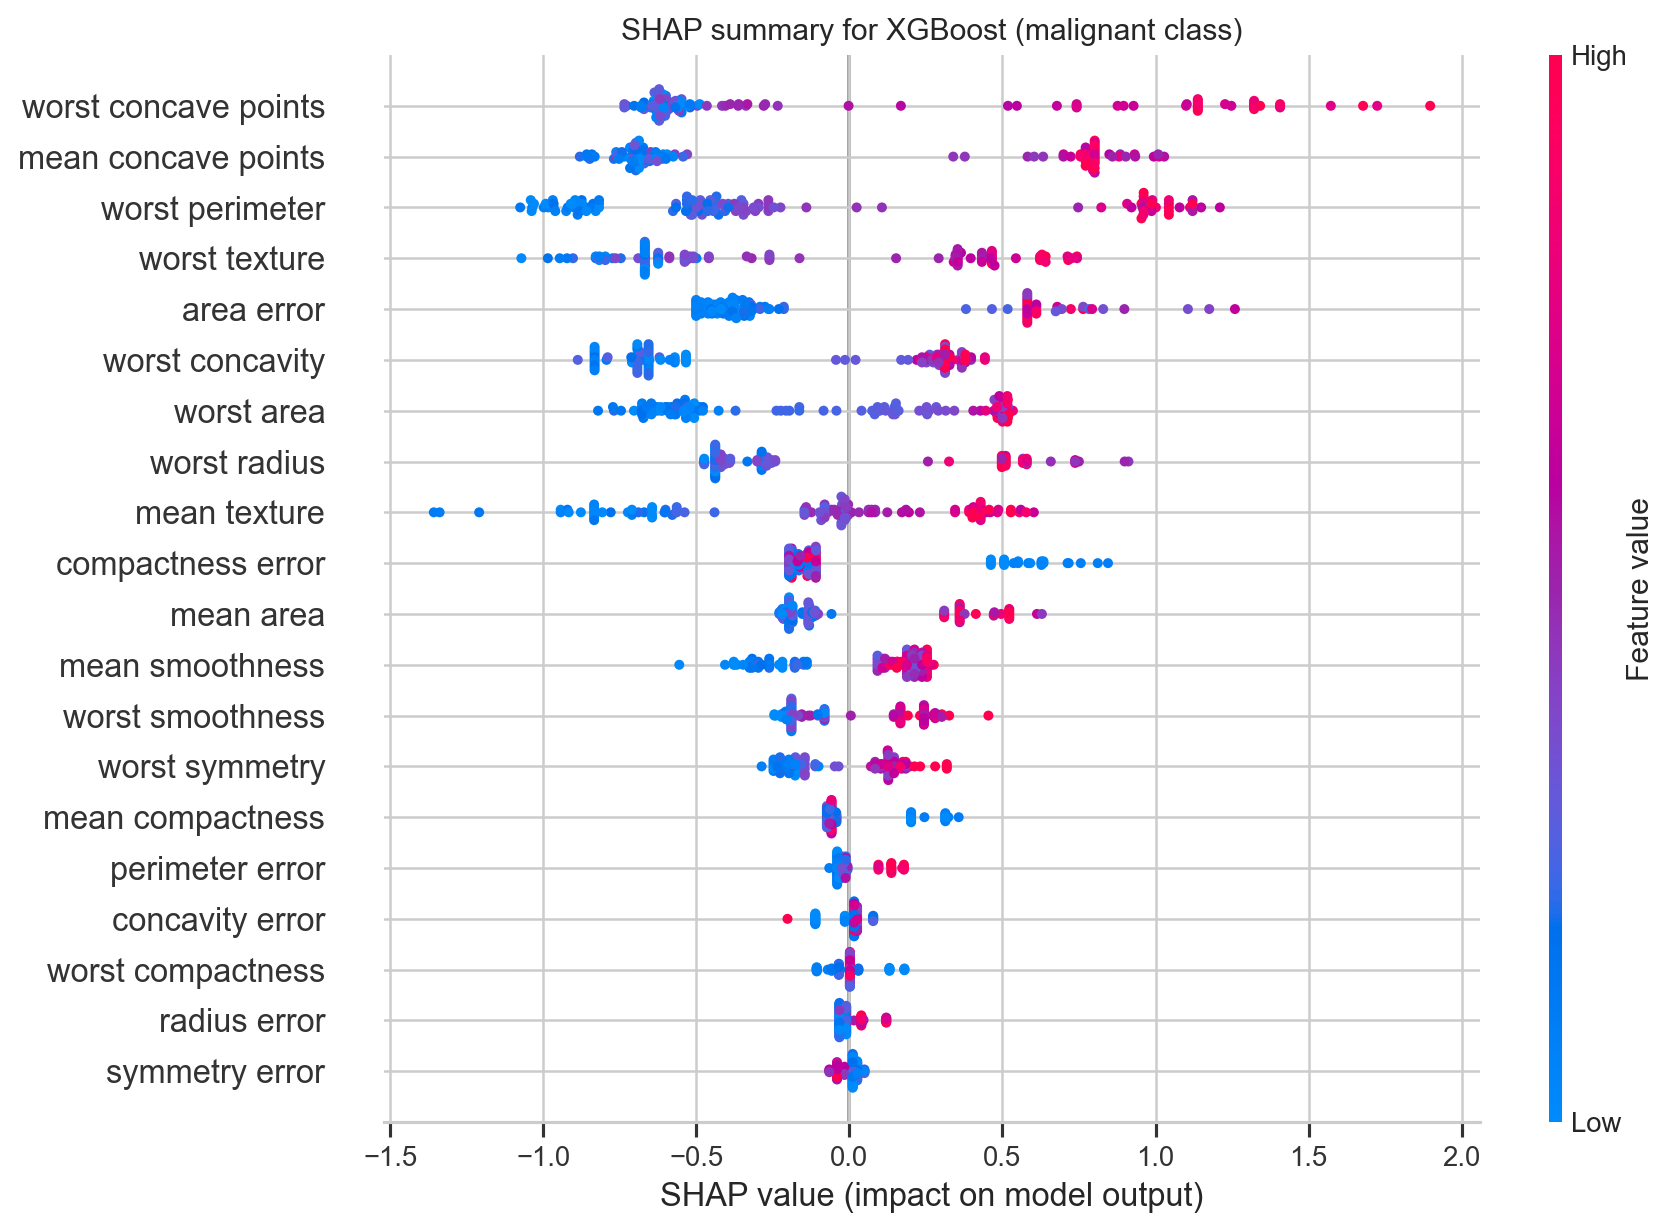

Best QSVM by malignant recall, then F1: QSVM ZFeatureMap


,original_patient_row,actual,predicted,decision_score,absolute_distance_from_boundary,why_it_may_be_hard
10,205,Malignant,Benign,-0.004314,0.004314,The signed SVM score shows how close the case ...
11,75,Malignant,Benign,-0.044454,0.044454,The signed SVM score shows how close the case ...
8,563,Malignant,Benign,-0.132826,0.132826,The signed SVM score shows how close the case ...
9,277,Malignant,Benign,-0.173701,0.173701,The signed SVM score shows how close the case ...
7,207,Malignant,Benign,-0.184316,0.184316,The signed SVM score shows how close the case ...
0,99,Malignant,Benign,-0.244981,0.244981,The signed SVM score shows how close the case ...
2,73,Malignant,Benign,-0.288472,0.288472,The signed SVM score shows how close the case ...
1,318,Benign,Malignant,0.403255,0.403255,The signed SVM score shows how close the case ...
3,208,Benign,Malignant,0.417627,0.417627,The signed SVM score shows how close the case ...
4,86,Malignant,Benign,-0.514753,0.514753,The signed SVM score shows how close the case ...


In [11]:
# Use the trained all-feature XGBoost pipeline and scale test rows as it expects.
xgboost_search = classical_searches[("XGBoost", "All 30 features")]
xgboost_pipeline = xgboost_search.best_estimator_
xgboost_model = xgboost_pipeline.named_steps["model"]
xgboost_test_scaled = xgboost_pipeline.named_steps["scale"].transform(X_test)

# Compute SHAP values for the test set and select the malignant output if needed.
tree_explainer = shap.TreeExplainer(xgboost_model)
shap_values = tree_explainer.shap_values(xgboost_test_scaled)
if isinstance(shap_values, list):
    shap_values_for_plot = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_values_for_plot = np.asarray(shap_values)[:, :, 1]
else:
    shap_values_for_plot = shap_values

# Save mean absolute SHAP values so the most useful features can be listed.
shap_importance = pd.DataFrame({
    "feature": list(X.columns),
    "mean_absolute_shap": np.mean(np.abs(shap_values_for_plot), axis=0),
}).sort_values("mean_absolute_shap", ascending=False)
shap_importance.to_csv(RESULTS_DIR / "shap_feature_importance.csv", index=False)
display(shap_importance.head(10))

# Save the SHAP feature summary for the malignant-class prediction.
shap.summary_plot(
    shap_values_for_plot,
    xgboost_test_scaled,
    feature_names=list(X.columns),
    show=False,
    plot_size=(10, 7),
)
shap_figure = plt.gcf()
shap_figure.axes[0].set_title("SHAP summary for XGBoost (malignant class)")
save_figure(shap_figure, RESULTS_DIR / "shap_xgboost_summary.png")

# Find errors from the QSVM with the higher malignant recall, then F1.
best_qsvm_name = max(
    ["QSVM ZFeatureMap", "QSVM ZZFeatureMap"],
    key=lambda name: (quantum_model_results[name]["recall"], quantum_model_results[name]["f1"]),
)
best_qsvm = quantum_model_results[best_qsvm_name]
wrong_positions = np.where(best_qsvm["y_pred"] != y_test.to_numpy())[0]
wrong_rows = []
for test_position in wrong_positions:
    wrong_rows.append({
        "original_patient_row": int(test_indices[test_position]),
        "actual": "Malignant" if y_test.iloc[test_position] == 1 else "Benign",
        "predicted": "Malignant" if best_qsvm["y_pred"][test_position] == 1 else "Benign",
        "decision_score": float(best_qsvm["y_score"][test_position]),
        "absolute_distance_from_boundary": abs(float(best_qsvm["y_score"][test_position])),
        "why_it_may_be_hard": "The signed SVM score shows how close the case is to the learned boundary.",
    })
wrong_patient_table = pd.DataFrame(wrong_rows).sort_values("absolute_distance_from_boundary")
wrong_patient_table.to_csv(RESULTS_DIR / "qsvm_misclassified_test_patients.csv", index=False)
print("Best QSVM by malignant recall, then F1:", best_qsvm_name)
display(wrong_patient_table.head(10))

## Step 9: Final comparison

The final table includes all classical runs and the two main QSVMs. ROC curves show ranking quality across thresholds; the bar chart compares malignant-class F1. The saved CSV tables and PNG figures can be used outside the notebook.

,model,features_used,accuracy,precision,recall,f1,roc_auc,training_time_s
0,SVM (linear),All 30 features,0.982456,1.000000,0.952381,0.975610,0.996362,0.146050
1,Random Forest,All 30 features,0.973684,1.000000,0.928571,0.962963,0.992890,1.836112
2,SVM (RBF),All 30 features,0.973684,1.000000,0.928571,0.962963,0.992725,0.140487
7,Logistic Regression,PCA 4 components,0.973684,1.000000,0.928571,0.962963,0.998016,0.171704
8,SVM (linear),PCA 4 components,0.973684,1.000000,0.928571,0.962963,0.997685,0.120246
3,Logistic Regression,All 30 features,0.964912,0.975000,0.928571,0.951220,0.996032,0.189629
4,XGBoost,All 30 features,0.964912,1.000000,0.904762,0.950000,0.994048,1.192640
9,Random Forest,PCA 4 components,0.956140,0.974359,0.904762,0.938272,0.993882,1.553271
10,SVM (RBF),PCA 4 components,0.947368,0.973684,0.880952,0.925000,0.996693,0.157614
11,Decision Tree,PCA 4 components,0.938596,0.948718,0.880952,0.913580,0.926587,0.145403


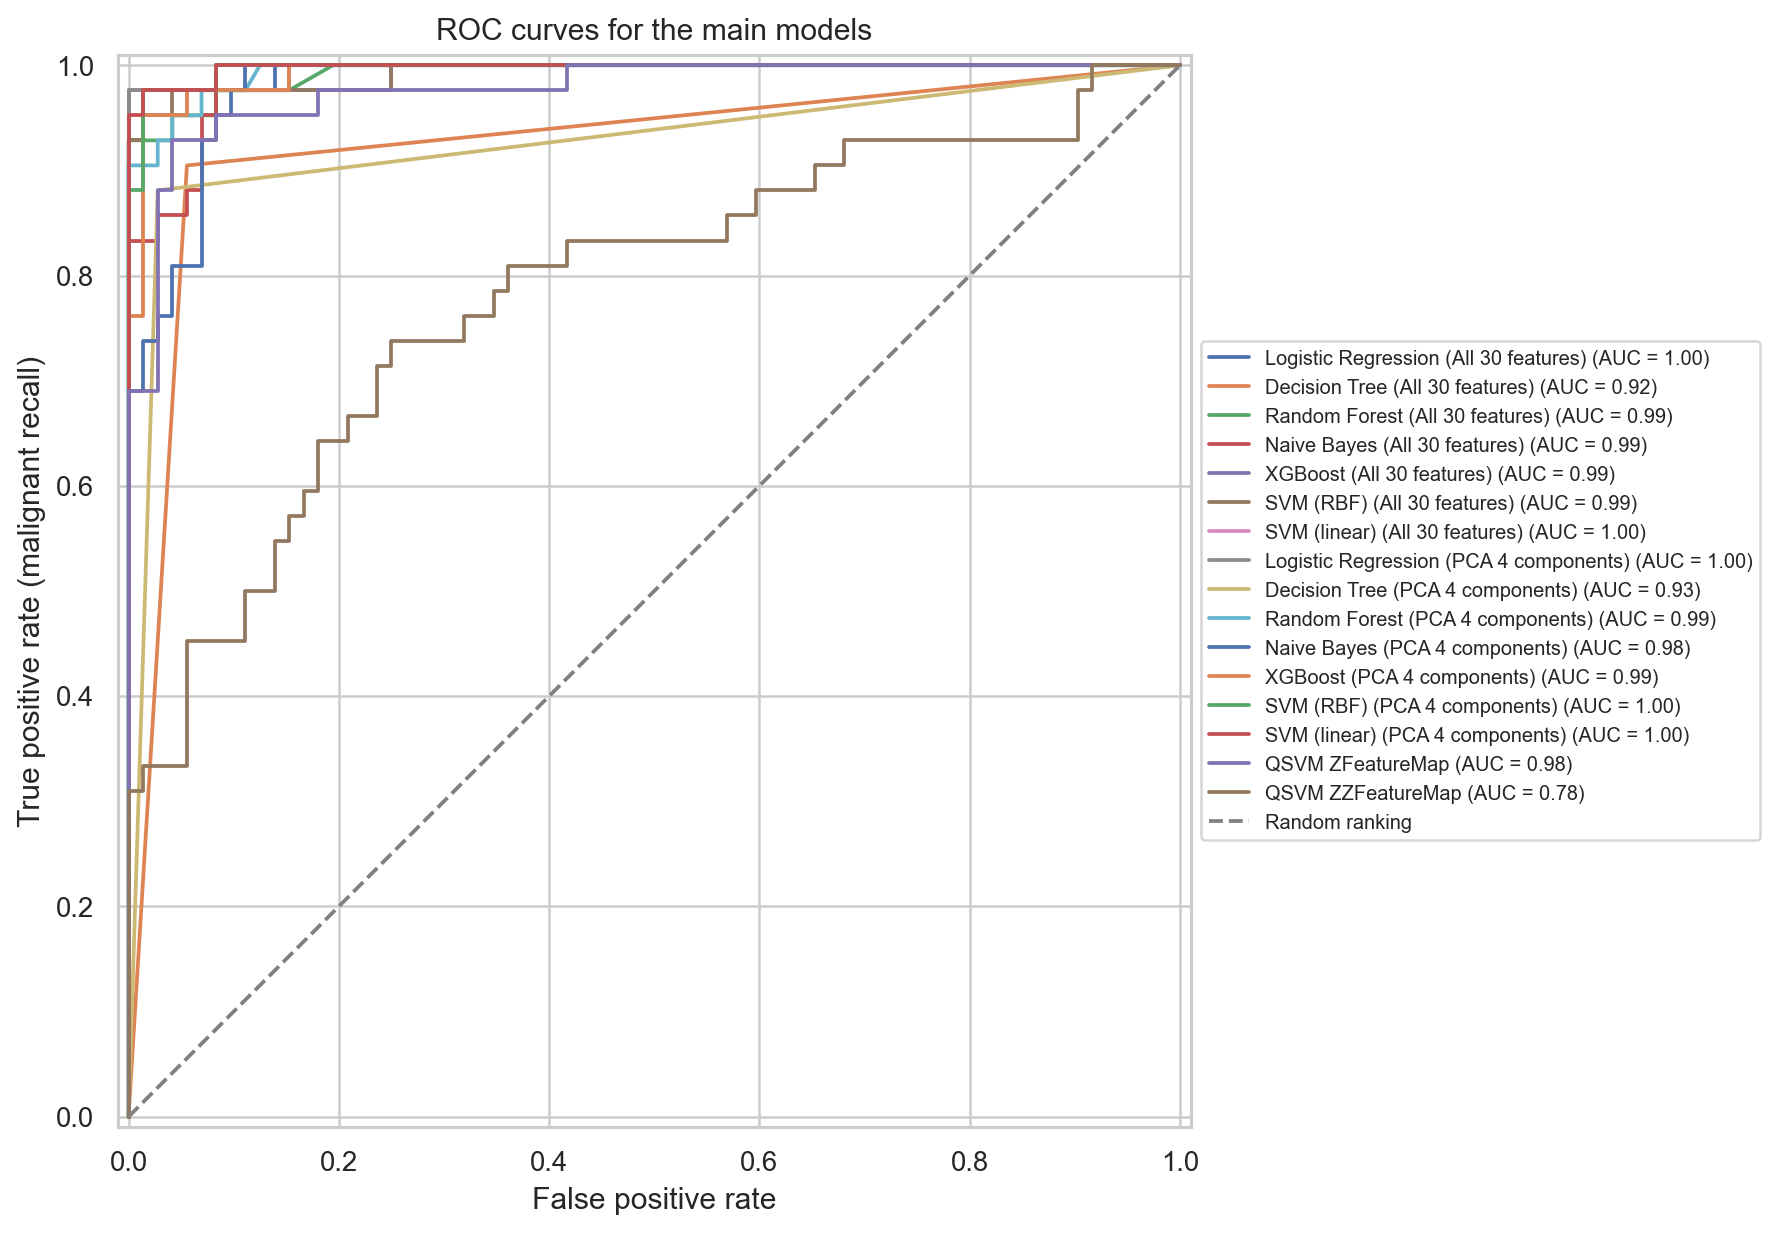

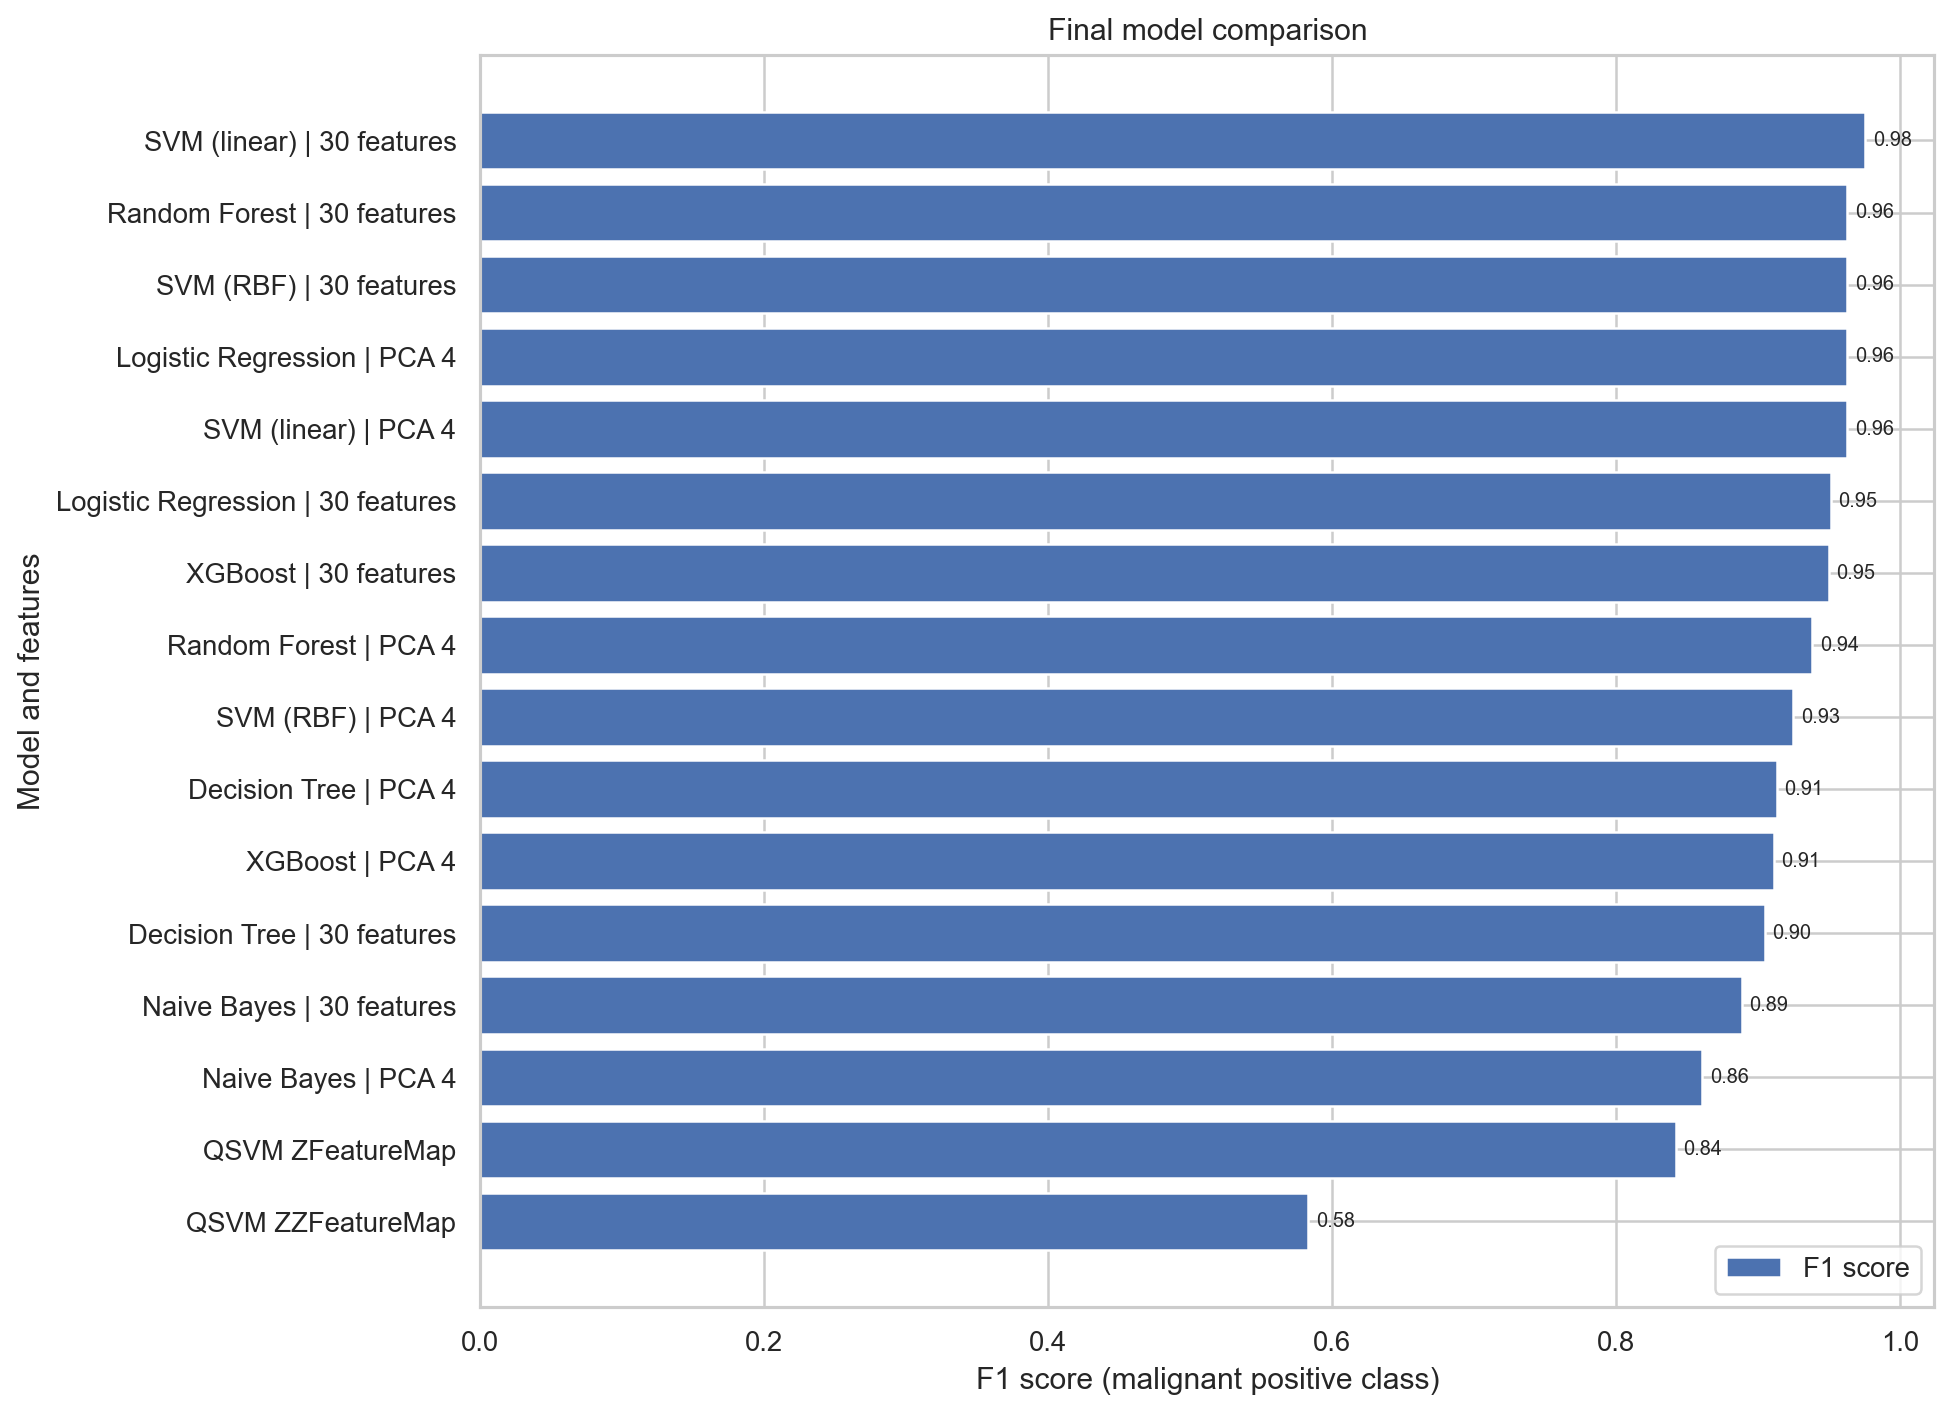

Best overall by test F1: SVM (linear) | All 30 features | F1: 0.976
Best QSVM by malignant recall, then F1: QSVM ZFeatureMap | recall: 0.762 | F1: 0.842
All tables and figures are saved in: D:\quantumgroup\wdbc-qsvm\results


In [12]:
# Combine the classical and main quantum test results into one final table.
final_rows = []
for _, row in classical_results.iterrows():
    final_rows.append({
        "model": row["model"],
        "features_used": row["features_used"],
        "accuracy": row["accuracy"],
        "precision": row["precision"],
        "recall": row["recall"],
        "f1": row["f1"],
        "roc_auc": row["roc_auc"],
        "training_time_s": row["training_time_s"],
    })
for model_name in ["QSVM ZFeatureMap", "QSVM ZZFeatureMap"]:
    result = quantum_model_results[model_name]
    final_rows.append({
        "model": model_name,
        "features_used": result["features_used"],
        "accuracy": result["accuracy"],
        "precision": result["precision"],
        "recall": result["recall"],
        "f1": result["f1"],
        "roc_auc": result["roc_auc"],
        "training_time_s": result["training_time_s"],
    })
final_comparison = pd.DataFrame(final_rows).sort_values("f1", ascending=False)
final_comparison.to_csv(RESULTS_DIR / "final_comparison.csv", index=False)
display(final_comparison)

# Draw ROC curves using each model's saved continuous decision scores.
fig, ax = plt.subplots(figsize=(9, 7))
for key, saved in classical_predictions.items():
    model_name, feature_set = key
    display_name = model_name + " (" + feature_set + ")"
    RocCurveDisplay.from_predictions(
        y_test,
        saved["y_score"],
        name=display_name,
        ax=ax,
    )
for model_name in ["QSVM ZFeatureMap", "QSVM ZZFeatureMap"]:
    result = quantum_model_results[model_name]
    RocCurveDisplay.from_predictions(
        y_test,
        result["y_score"],
        name=model_name,
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
ax.set_title("ROC curves for the main models")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (malignant recall)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save_figure(fig, RESULTS_DIR / "roc_curves_all_main_models.png")

# Compare malignant-class F1 for every row in the final table using readable labels.
fig, ax = plt.subplots(figsize=(11, 8))
short_labels = []
for _, row in final_comparison.iterrows():
    if row["model"].startswith("QSVM"):
        short_labels.append(row["model"])
    else:
        feature_label = "30 features" if row["features_used"] == "All 30 features" else "PCA 4"
        short_labels.append(row["model"] + " | " + feature_label)
bars = ax.barh(short_labels, final_comparison["f1"], label="F1 score")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.invert_yaxis()
ax.set_title("Final model comparison")
ax.set_xlabel("F1 score (malignant positive class)")
ax.set_ylabel("Model and features")
ax.legend(handles=[bars], labels=["F1 score"])
save_figure(fig, RESULTS_DIR / "final_model_comparison.png")

# Print the best overall model and best QSVM using the stated selection rules.
best_overall_row = final_comparison.iloc[0]
print("Best overall by test F1:", best_overall_row["model"], "|", best_overall_row["features_used"], "| F1:", round(best_overall_row["f1"], 3))
print("Best QSVM by malignant recall, then F1:", best_qsvm_name, "| recall:", round(best_qsvm["recall"], 3), "| F1:", round(best_qsvm["f1"], 3))
print("All tables and figures are saved in:", RESULTS_DIR)

## Step 10: Optional noise demo

This project keeps the main comparison focused on noiseless statevector simulation. A realistic hardware noise demo is omitted because it would add another simulator configuration and runtime; the circuit is still simulated, not run on a quantum device.